# Quality Control for Imaging-Based Spatial Transcriptomics (Xenium)

## Introduction

In our previous modules ([Notebook 04](./04-quality_control_VisiumHD_segmented.ipynb) and [Notebook 05](./05-quality_control_VisiumHD_binned.ipynb)), we tackled quality control (QC) in sequencing-based Visium HD data, relying on global count distributions, mitochondrial read percentages, and local spatial Z-scores. As we transition to _in situ_ subcellular imaging platforms such as **10x Genomics Xenium**, our QC strategy must fundamentally adapt to the underlying physics and optics of targeted cyclic fluorescence imaging.

Unlike unbiased poly-A capture sequencing, [imaging-based spatial transcriptomics](../assets/notes/03-preprocessing_data_structures.md) quantifies pre-selected gene panels by hybridizing fluorescent padlock/circularizing probes followed by repeated rounds of optical decoding. This distinct architecture introduces three platform-specific error modes that shape our analytical workflow:

1. **Optical Noise & Non-Specific Binding Floor:** Targeted hybridization is susceptible to off-target probe binding, optical cross-talk, and barcode miscalling during sequential fluorescence cycles ([Hallinan et al., 2026](https://doi.org/10.7554/eLife.107070.3)). Rather than relying on mitochondrial read ratios (which are absent in targeted panels lacking mitochondrial genes) Xenium integrates dedicated negative controls, i.e., negative control probes, unassigned decoding codewords, and genomic control probes. These built-in controls establish an empirical baseline that allows us to quantify technical false-positive rates and model transcript-level reliability directly.
2. **Inferred Morphological Boundaries & Segmentation Artifacts:** Transcripts in Xenium are assigned to individual cells _post hoc_ via optical nuclear/membrane segmentation algorithms. Imperfect boundary delineation can introduce under-segmentation (pooling distinct cells into artificial doublets), over-segmentation (splitting single cells into fragments), and anucleate cell polygons derived solely from background auto-fluorescent debris. Evaluating nuclear and cellular areas alongside nucleus-to-cell area ratios is therefore critical to ensure morphological integrity.
3. **Microscopic Seams & Physical Coordinate Context:** Platform-level mechanical artifacts—including optical field-of-view (FOV) stitching seams, detached floating debris, and mechanical shear along coverslip margins—cannot be diagnosed from isolated tabular metrics. These anomalies only become evident when per-cell statistics and nearest-neighbor distance metrics are mapped back onto continuous spatial coordinates.

## Learning objectives

- Distinguish negative control probes, unassigned decoding codewords, and genomic controls within Xenium output to quantify the technical false-discovery baseline.
- Calculate library size and gene complexity tailored to targeted panels, accounting for gene-panel size saturation rather than genome-wide sequencing assumptions.
- Diagnose over-segmentation, doublets, and cellular fragments by profiling nuclear and cell polygon areas alongside nucleus-to-cell area ratios.
- Detect detached cellular debris and edge-disruption artifacts by computing physical nearest-neighbor distance distributions across the slide.
- Model the empirical mean–variance relationship across biological targets relative to negative control distributions to identify weakly detected or noisy transcripts.
- Synthesize per-cell, spatial, and morphological indicators into a multi-tiered filtering threshold, prune low-confidence observations, and serialize a clean `SpatialFeatureExperiment` object.

## Environment setup & data import

### Loading libraries

We leverage the `SpatialFeatureExperiment` (SFE) data structure and the `Voyager` exploratory spatial analysis ecosystem (following workflows aligned with the official [Voyager Xenium vignette](https://pachterlab.github.io/voyager/articles/vig5_xenium.html)) to systematically diagnose error modes, dissect probe performance, and build a principled, defensible filtering strategy for downstream biological discovery.

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core spatial transcriptomics data structures & visualization
  library(SpatialFeatureExperiment)
  library(Voyager)

  # Single-cell QC metrics
  library(scuttle)
  library(BiocNeighbors) # k-NN spatial graph outlier detection

  # Plotting, matrix layouts & palettes
  library(ggplot2)
  library(patchwork)
  library(ggforce)       # Pairwise facet_matrix for QC distributions
  library(scales)

  # Data wrangling & parquet I/O
  library(dplyr)
  library(stringr)
  library(arrow)

  # Object serialization
  library(alabaster.sfe)
}))

### Visual styling & plot aesthetics

To ensure consistent, publication-grade figures across our QC diagnostics, we configure a clean `ggplot2` baseline theme. Rather than relying on heavy default contrast or stark ungridded panels, we establish clean typography, muted facet strip headers, and subtle major gridlines for all standard analytical plots and histograms (`plotColDataHistogram()`).

In [2]:
# Define a clean, publication-grade theme for diagnostic plots
theme_clean <- theme_minimal(base_size = 11) + 
  theme(
    # Clean facet header strips
    strip.background    = element_rect(fill = "#f1f3f5", colour = "#ced4da", linewidth = 0.5), 
    strip.text          = element_text(face = "bold", color = "#212529", size = 10), 

    # Subtle panel structure
    panel.grid.minor    = element_blank(), 
    panel.grid.major    = element_line(colour = "#e9ecef", linewidth = 0.4), 
    panel.border        = element_rect(colour = "#ced4da", fill = NA, linewidth = 0.5), 

    # Axis typography
    axis.title.x        = element_text(face = "bold", size = 10, margin = margin(t = 8)),
    axis.title.y        = element_text(face = "bold", size = 10, margin = margin(r = 8)),
    axis.text.x         = element_text(colour = "#495057", size = 9, margin = margin(t = 6)),
    axis.text.y         = element_text(colour = "#495057", size = 9, margin = margin(r = 6)),

    # Spacing
    plot.margin         = margin(t = 10, r = 10, b = 10, l = 10),

    # Legend spacing & typography
    legend.title        = element_text(face = "bold", size = 10, margin = margin(b = 6, r = 6)),
    legend.text         = element_text(colour = "#495057", size = 9),
  )

# Set as default theme for all downstream plots
theme_set(theme_clean)

> For `Voyager`'s dedicated spatial plotting functions (`plotSpatialFeature()`, `plotGeometry()`), we rely on Voyager's built-in spatial themes rather than forcing `theme_clean`. By default, Voyager renders clean, coordinate-free tissue maps (`theme_void()`), or enables native Cartesian gridlines when setting `show_axes = TRUE` (`theme_bw()`). Because these spatial functions enforce strict 1:1 physical aspect ratios alongside zero-margin spatial defaults, we may occasionally notice minor text or legend margin clipping at the outer canvas boundaries depending on viewport dimensions in the current configuration of the Jupyter notebook.

### Restoring the Xenium dataset

We begin by loading the cropped `SpatialFeatureExperiment` (`sfe`) object assembled during our initial data ingestion module ([Notebook 02](./02-data_ingestion_SpatialFeatureExperiment_object.ipynb)).

Because Xenium datasets encompass rich morphological layers, standard file formats like `.rds` or basic HDF5 wrappers strip or corrupt complex `sf` geometric attributes. To ensure lossless reproducibility and retain the complete geometry hierarchy, we restore the object using `alabaster.sfe::readObject()` (or `alabaster.base::readObject()`).

In [3]:
# Load the pre-cropped SpatialFeatureExperiment object
out_path <- "output/sfe_xenium"

sfe <- readObject(out_path)

# Verify the restored object dimensions, metadata, and spatial geometries
sfe

>>> Reading SpatialExperiment

>>> Reading colgeometries



class: SpatialFeatureExperiment 
dim: 541 52569 
metadata(1): Samples
assays(1): counts
rownames(541): ABCC8 ACP5 ... UnassignedCodeword_0330
  UnassignedCodeword_0338
rowData names(3): ID Symbol Type
colnames(52569): ablhnkec-1 ablhpkkh-1 ... oikdmkkf-1 oikeebja-1
colData names(9): transcript_counts control_probe_counts ...
  nucleus_area sample_id
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : x_centroid y_centroid
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (MULTIPOLYGON), nucSeg (MULTIPOLYGON) 

Graphs:
sample01: 

> In modern Bioconductor versions, `alabaster` restores sparse HDF5 count matrices as `SVT_SparseMatrix` (Sparse Vector Tree) objects. While memory-efficient, certain C++ kernels in downstream QC packages (such as `scuttle::addPerCellQCMetrics`) expect standard double-precision sparse pointers (`CsparseMatrix` / `dgCMatrix`). To prevent type-dispatch conflicts across Bioconductor packages, we cast the assay matrix to `dgCMatrix` immediately upon loading.

In [4]:
# Ensure the count assay uses standard in-memory dgCMatrix representation
counts(sfe) <- as(counts(sfe), "dgCMatrix")

`imgData(sfe)` contains no raster image: full-resolution Xenium TIFF stacks span tens of gigabytes and were omitted during initial assembly ([Notebook 00](./00-assembling_spatial_transcriptomics_datasets.ipynb)). We previously generated a spatial coordinate footprint of this cropped area:

![Xenium Cropped ROI](../assets/img/xenium_p2_crc_subset.png)

In `sfe`, we can inspect tissue architecture and cell density directly from the native vector polygons (`cellSeg` and `nucSeg`).

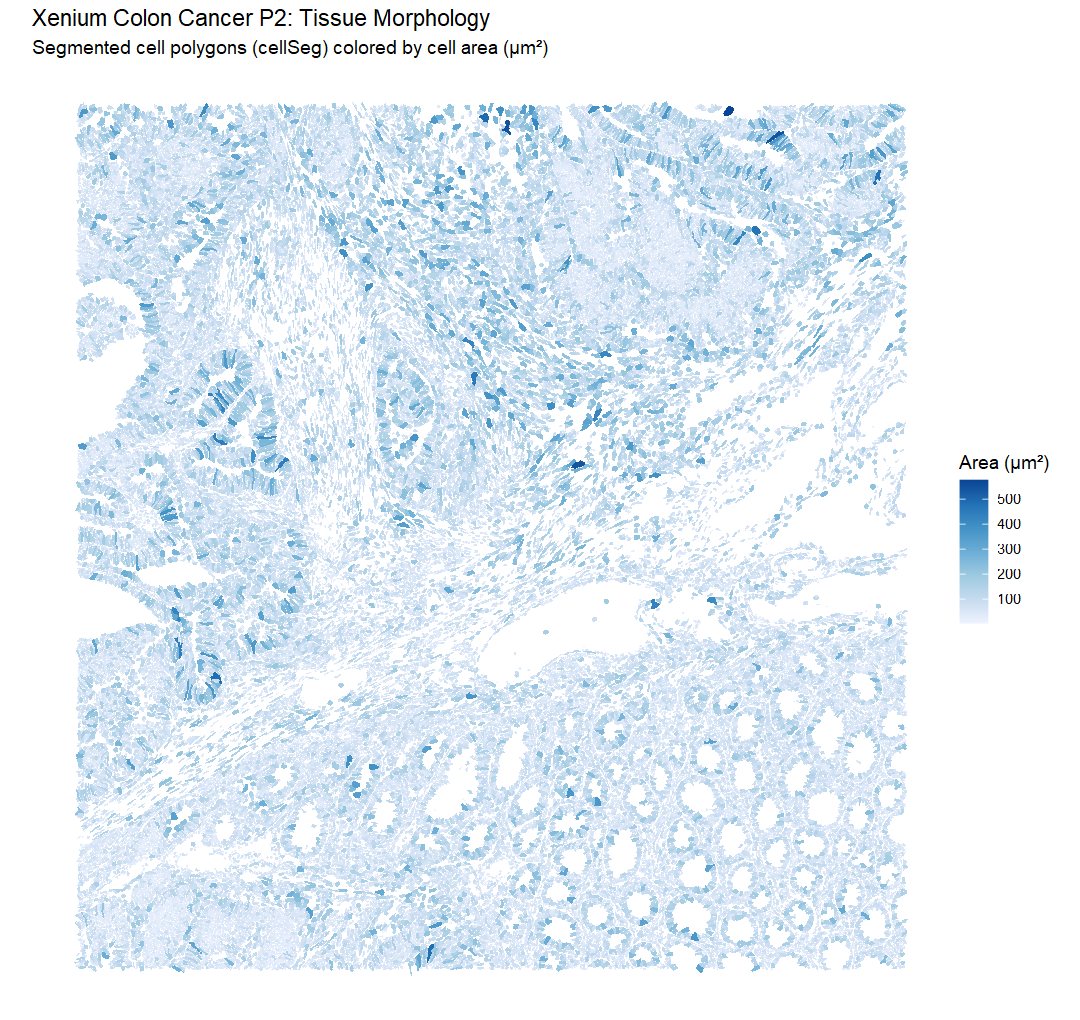

In [5]:
# Set canvas dimensions a little wider
options(repr.plot.width = 9, repr.plot.height = 8.5)

# Check tissue layout and cell density via segmented polygons
plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "cell_area") + 
  # scale_fill_gradientn(colors = pals::jet(), trans = "log10") + 
  labs(
    title = "Xenium Colon Cancer P2: Tissue Morphology", 
    subtitle = "Segmented cell polygons (cellSeg) colored by cell area (µm²)", 
    fill = "Area (µm²)"
  )

## Profiling optical noise & negative controls

### Panel composition & per-cell metric calculation

#### Defining control feature subsets in rowData

As seen in the `sfe` summary printout, `rowData(sfe)` contains an additional metadata column, `Type`, absent in our previous `spe` or `se` objects. 

In sequencing-based Visium HD, QC relied on mitochondrial read percentages as a proxy for cellular damage. In targeted Xenium panels (which omit mitochondrial genes), technical noise is evaluated directly using the control feature categories recorded in `rowData(sfe)[["Type"]]`.

In [6]:
# Show SFE's rowData columns
rowData(sfe)[c("ID", "Type")]

DataFrame with 541 rows and 2 columns
                                            ID                Type
                                   <character>         <character>
ABCC8                          ENSG00000006071     Gene Expression
ACP5                           ENSG00000102575     Gene Expression
ACTA2                          ENSG00000107796     Gene Expression
ADH1C                          ENSG00000248144     Gene Expression
ADRA2A                         ENSG00000150594     Gene Expression
...                                        ...                 ...
UnassignedCodeword_0289 UnassignedCodeword_0.. Unassigned Codeword
UnassignedCodeword_0292 UnassignedCodeword_0.. Unassigned Codeword
UnassignedCodeword_0298 UnassignedCodeword_0.. Unassigned Codeword
UnassignedCodeword_0330 UnassignedCodeword_0.. Unassigned Codeword
UnassignedCodeword_0338 UnassignedCodeword_0.. Unassigned Codeword

We can inspect the composition of our **541-plex panel**, by tabulating the feature count and percentage allocated to each category alongside representative identifiers.

In [7]:
# Summarize feature categories across the 541-plex panel
feature_summary <- as.data.frame(rowData(sfe)) |>
  mutate(feature = rownames(sfe)) |>
  group_by(Type) |>
  summarise(
    n_features = n(), 
    pct_panel  = sprintf("%.1f%%", 100 * n() / nrow(sfe)), 
    examples   = paste(head(feature, 2), collapse = ", "), 
    .groups    = "drop"
  ) |>
  arrange(desc(n_features))

# Inspect representative probe names
feature_summary

Type,n_features,pct_panel,examples
<chr>,<int>,<chr>,<chr>
Gene Expression,422,78.0%,"ABCC8, ACP5"
Unassigned Codeword,58,10.7%,"UnassignedCodeword_0005, UnassignedCodeword_0007"
Negative Control Codeword,41,7.6%,"NegControlCodeword_0500, NegControlCodeword_0501"
Negative Control Probe,20,3.7%,"NegControlProbe_00042, NegControlProbe_00041"


Across our 541-plex panel, **119 features (22.0%)** are dedicated technical controls distinguishing two fundamentally different sources of experimental error:

- **Negative Control Probes (`NegControlProbe_`, 20 features / 3.7%):** Physical oligonucleotide probes targeting artificial non-biological sequences absent from the human genome. Because they undergo the full hybridization, ligation, and rolling-circle amplification workflow, their signal measures the **hybridization background floor** (non-specific binding and off-target probe annealing).
- **Negative Control Codewords (`NegControlCodeword_`, 41 features / 7.6%):** Valid optical barcodes deliberately left unassigned to any physical probe. Because no matching probe exists in the tissue, any detected signal represents pure **optical decoding error** (fluorescence cross-talk or miscalled cycle signals), which 10x Genomics uses to calibrate transcript quality scores (Q-values).
- **Unassigned Codewords (`UnassignedCodeword_`, 58 features / 10.7%):** Unused mathematical codeword space within the optical codebook, expected to yield negligible signal and monitored for overall decoding fidelity.

#### Quantifying per-cell background metrics with `scuttle`

To profile technical noise systematically across our cells, we construct logical masks for each control category and package them into a named list (`neg_subsets`). This list serves a dual purpose in our downstream QC pipeline:

1. Passing `neg_subsets` directly into `scuttle::addPerCellQCMetrics()` automatically calculates the library fraction (`_percent`) and raw counts (`_sum`) attributed to non-specific binding and decoding error for every individual cell.
2. Inverting the composite `any_neg` mask allows us to filter out technical control probes when computing genuine cellular transcript counts and gene complexity metrics.

In [8]:
# Define logical masks for each negative control category
feature_types <- rowData(sfe)[["Type"]]

neg_subsets <- list(
  negProbe    = feature_types == "Negative Control Probe", 
  negCodeword = feature_types == "Negative Control Codeword", 
  unassigned  = feature_types == "Unassigned Codeword", 
  any_neg     = feature_types != "Gene Expression"
)

We now evaluate the extent of technical contamination across _individual cell polygons_ using `scuttle::addPerCellQCMetrics()`. For each cell, this function computes the total library size (`sum`), the number of detected features (`detected`), and appends subset-specific metrics based on our `neg_subsets` list directly into `colData(sfe)`:

- **Raw Subset Counts (`subsets_*_sum`):** The absolute number of transcripts assigned to a given control category within the cell polygon.
- **Control Percentage (`subsets_*_percent`):** The fraction of the cell's total library attributed to that control category.

In [9]:
# Compute per-cell total counts and percentage for each control subset
sfe <- addPerCellQCMetrics(sfe, subsets = neg_subsets)

Warning message in addPerCellQCMetrics(sfe, subsets = neg_subsets):
"'addPerCellQCMetrics' est obsolète.
Utilisez plutôt ‘scrapper::quickRnaQc.se’.
Voir help("Deprecated")"
Warning message in .per_cell_qc_metrics(assay(x, assay.type), subsets = subsets, :
"'perCellQCMetrics' est obsolète.
Utilisez plutôt ‘scrapper::computeRnaQcMetrics’.
Voir help("Deprecated")"


> Recent Bioconductor updates may suggest using `scrapper::computeRnaQcMetrics()` instead of `scuttle::addPerCellQCMetrics()`. `scrapper` is a C++-accelerated implementation optimized for massive, multi-million cell atlases. For standard single-slide and cropped spatial analyses, `scuttle::addPerCellQCMetrics()` remains the standard high-level Bioconductor method because it automatically appends all named subset metrics (`subsets_*_sum`, `subsets_*_percent`) directly into `colData(sfe)` in a single call.

In [10]:
# Inspect a few newly calculated QC metrics in colData
qc_cols <- c(
  "sum", "detected", 
  "subsets_negProbe_sum", 
  "subsets_negCodeword_sum", 
  "subsets_unassigned_percent", 
  "subsets_any_neg_percent"
)

colData(sfe)[, qc_cols] |> head()

DataFrame with 6 rows and 6 columns
                 sum  detected subsets_negProbe_sum subsets_negCodeword_sum
           <numeric> <numeric>            <numeric>               <numeric>
ablhnkec-1       116        55                    0                       0
ablhpkkh-1       120        41                    0                       0
ablicbjh-1        89        48                    0                       0
ablilfnl-1        81        43                    0                       0
ablineen-1       145        57                    0                       0
ablioegm-1        71        42                    0                       0
           subsets_unassigned_percent subsets_any_neg_percent
                            <numeric>               <numeric>
ablhnkec-1                          0                       0
ablhpkkh-1                          0                       0
ablicbjh-1                          0                       0
ablilfnl-1                          0         

#### Handling empty cell segments and NaN values

In imaging-based spatial transcriptomics, cell boundaries are inferred optically from nuclear stains (DAPI) and cell boundary markers. Occasionally, a segmented cell polygon falls over a transcriptionally quiescent region (e.g., dense fibrotic collagen, an acellular mucus pocket, or an anucleate fragment) and captures **0 total transcripts** (sum = 0).

When `scuttle::addPerCellQCMetrics()` calculates technical control percentages, it divides the subset count by the total cell library. Thus, for cells with sum = 0, evaluating $\frac{0}{0}$ mathematically yields **`NaN`** (*Not a Number*). In R, logical comparisons involving `NaN` (such as `x == 0` or `x > 10`) evaluate to **`NA`**.

Consequently, to avoid propagating missing values into downstream filters and `sf` geometric overlays, we must explicitly account for these empty segments:

- When calculating summary statistics: use `na.rm = TRUE` (e.g. `mean(..., na.rm = TRUE)`).
- When creating boolean outlier masks: guard the condition with `!is.na()` (e.g. `!is.na(sfe[["subsets_any_neg_percent"]])`).

In [11]:
# Count how many cells have sum == 0
sum(colData(sfe)[["sum"]] == 0)
# sum(sfe[["sum"]] == 0)

[1] 166

### Statistical distributions & benchmark cross-validation

#### Relative percentage distributions & zero-inflation

Transcript abundance varies across tissue microenvironments (e.g., dense tumor vs. quiescent stroma). The relative control fraction (`_percent$`) normalizes for this variability, allowing us to detect cells affected by non-specific binding or decoding miscalls.

In [12]:
# Identify all percentage-based QC columns in colData
cols_percent <- grep("_percent$", names(colData(sfe)), value = TRUE)

Warning message:
"Removed 664 rows containing non-finite outside the scale range (`stat_bin()`)."


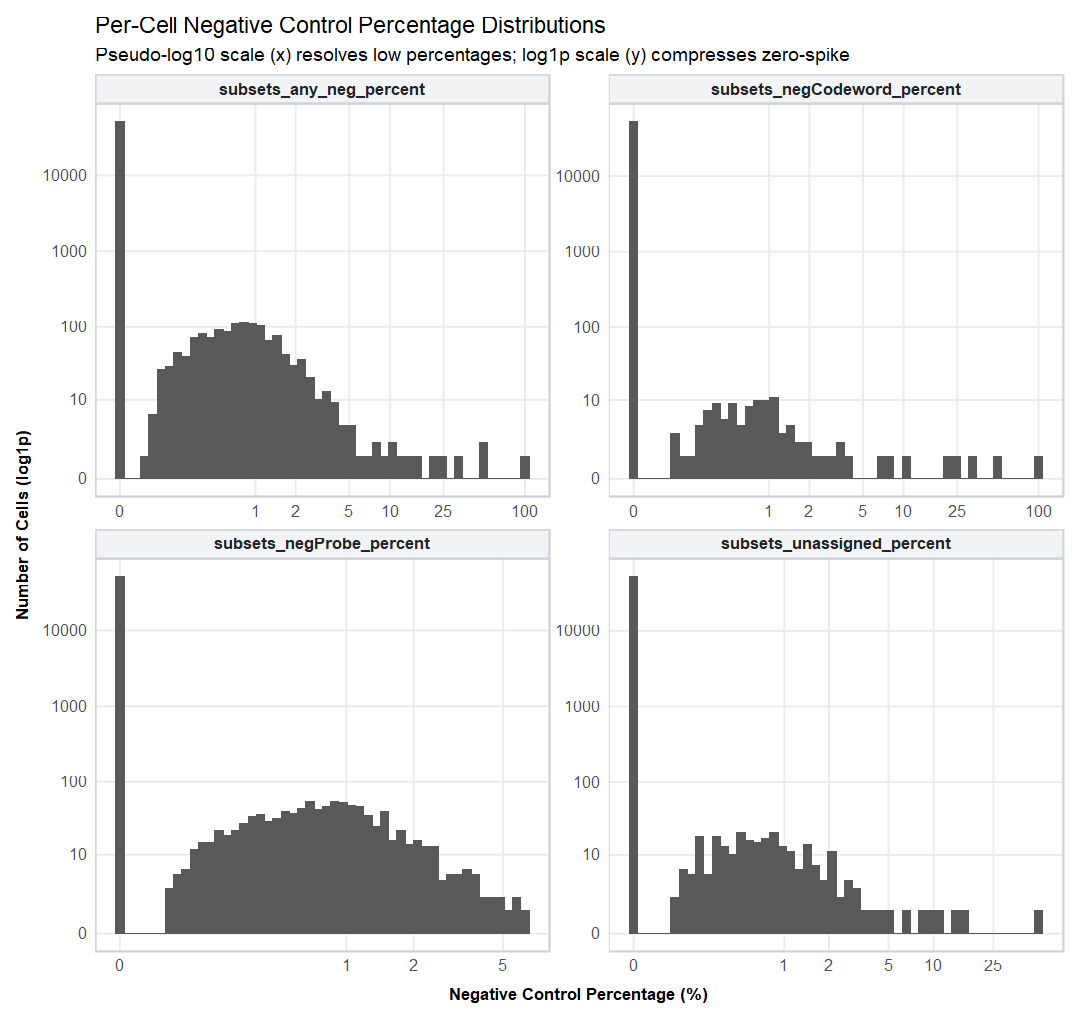

In [13]:
# Plot multi-panel histograms of control subsets on a logarithmic scale
plotColDataHistogram(sfe, feature = cols_percent, bins = 50, ncol = 2) + 
  scale_x_continuous(
    trans  = scales::pseudo_log_trans(base = 10, sigma = 0.1),
    breaks    = c(0, 1, 2, 5, 10, 25, 100), 
    # labels = function(x) paste0(x, "%")
  ) + 
  scale_y_continuous(
    transform = "log1p",  # ln(1 + x)
    breaks    = c(0, 10, 100, 1000, 10000, 100000), 
  ) + 
  labs(
    title = "Per-Cell Negative Control Percentage Distributions", 
    subtitle = "Pseudo-log10 scale (x) resolves low percentages; log1p scale (y) compresses zero-spike", 
    x = "Negative Control Percentage (%)", 
    y = "Number of Cells (log1p)"
  )

Technical noise is confined to a small fraction of cells. Most cells show strictly 0% background; non-zero cells peak below 1% and decay by 3–5%. Optical decoding errors (`negCodeword`) are nearly non-existent.

To measure this baseline with exact numbers, we calculate the proportion of cells with strictly zero technical background across each control category.

In [14]:
# Calculate the exact percentage of cells with strictly 0% technical background
zero_bg_pct <- vapply(
  cols_percent, 
  function(col) mean(colData(sfe)[[col]] == 0, na.rm = TRUE) * 100, 
  numeric(1)
) |> round(1)

# Display as a clean diagnostic table
data.frame(
  control_subset = names(zero_bg_pct), 
  pct_zero_cells = paste0(zero_bg_pct, "%")
)

control_subset,pct_zero_cells
<chr>,<chr>
subsets_negProbe_percent,98.1%
subsets_negCodeword_percent,99.8%
subsets_unassigned_percent,99.5%
subsets_any_neg_percent,97.5%


The empirical calculations demonstrate the high fidelity of this Xenium run:

- **Near-zero overall background:** **97.5% of all cells** harbor strictly **0% technical background** across all control categories combined (`subsets_any_neg_percent`). Technical noise is therefore not a widespread confounder, but an isolated phenomenon confined to a tiny minority (≈2.5%) of cells.
- **Robust hybridization specificity:** **98.1% of cells** contain zero off-target negative control probes (`negProbe`), confirming negligible non-specific binding.
- **Flawless optical decoding:** **99.8% of cells** exhibit zero false codewords (`negCodeword`), confirming that fluorescence cycle registration and barcode calling were virtually noise-free.

#### Count magnitude versus percentage distortions

Examining **absolute counts** (`_sum$`) contextualizes percentage values. In low-count cells (e.g., 20 total transcripts), a single stray probe yields an apparent 5% background. In high-count cells (800 transcripts), several probes represent < 0.5%. 

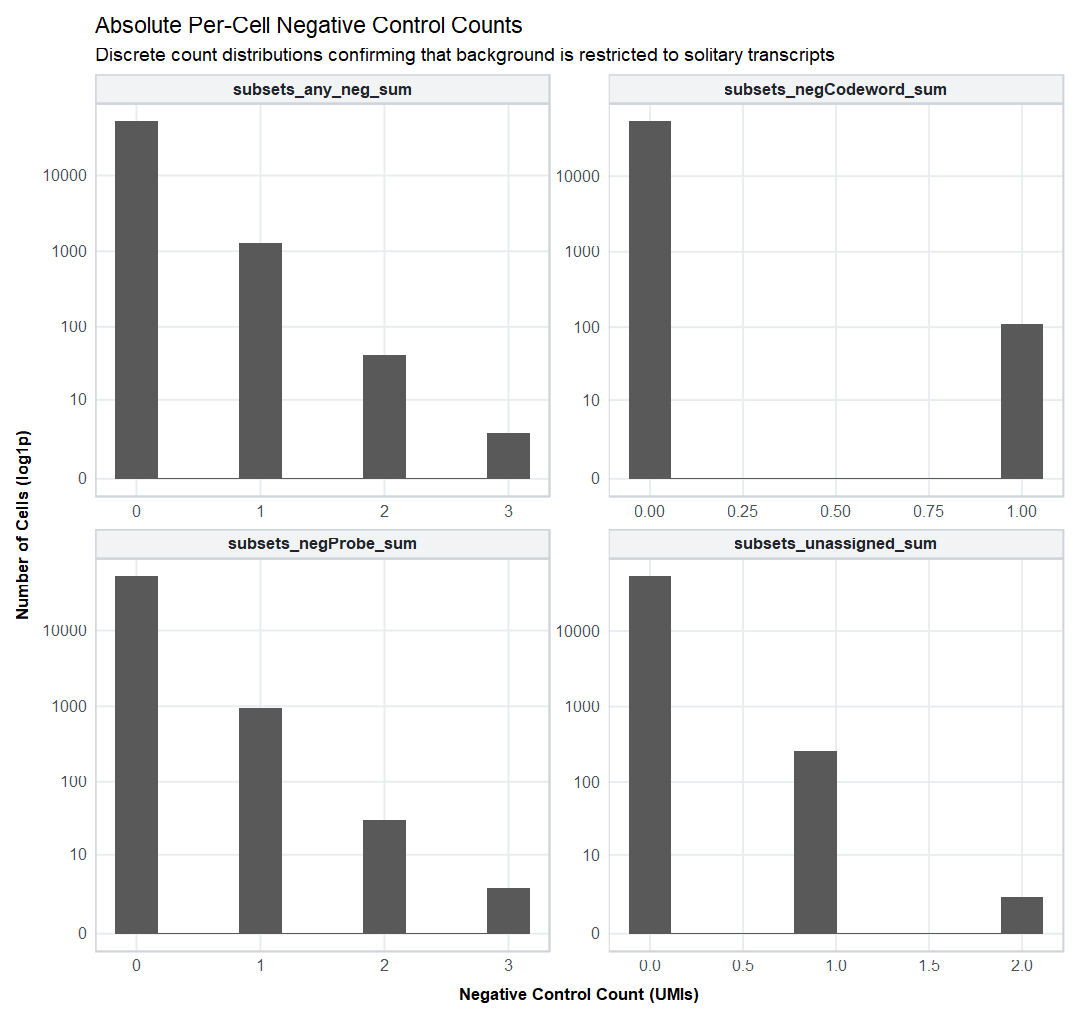

In [15]:
# Identify all raw count sum columns for control subsets
cols_sum <- names(colData(sfe))[str_detect(names(colData(sfe)), "_sum$")]

# Plot discrete per-cell count distributions with extended integer breaks
plotColDataHistogram(sfe, cols_sum, bins = 10, ncol = 2) + 
  scale_y_continuous(
    transform = "log1p", 
    breaks    = c(0, 10, 100, 1000, 10000, 100000)
  ) +
  labs(
    title    = "Absolute Per-Cell Negative Control Counts", 
    subtitle = "Discrete count distributions confirming that background is restricted to solitary transcripts", 
    x        = "Negative Control Count (UMIs)", 
    y        = "Number of Cells (log1p)"
  )

It is crucial to distinguish between the **119 control feature channels** measured in the assay and the **actual physical molecules detected** within a cell. Although our panel contains 119 distinct non-biological targets (20 probes, 41 codewords, 58 unassigned), optical specificity is sufficiently high that 97.5% of cells capture strictly 0 control transcripts. Even in the worst-case cells across all 52,569 profiles, we detect at most **3 stray control molecules in total** (`subsets_any_neg_sum <= 3`), with optical decoding errors never exceeding **1 miscall** (`subsets_negCodeword_sum <= 1`).

This physical magnitude directly explains the upper percentage tail:

$$
\text{Background } \% = \frac{\text{control counts}}{\text{total library size}} \times 100
$$

- In a robust epithelial tumor cell with **800 transcripts**, a stray molecule represents only $\frac{1}{800} \approx 0.1\%$.
- In a transcript-sparse cell or quiescent fragment with **15 transcripts**, that exact same solitary molecule registers as $\frac{1}{15} \approx 6.7\%$.

Cells exhibiting > 5% technical background are therefore **not** experiencing severe probe contamination or optical breakdown; rather, they are low-complexity segments whose small denominators mathematically amplify a solitary stray transcript.

Our empirical Bioconductor calculations directly mirror the [instrument-level metrics reported by 10x Genomics](../data/Human_Colon_Cancer_P2/reports/Xenium_V1_Human_Colon_Cancer_P2_CRC_Add_on_FFPE_analysis_summary.html) and associated summary (`metrics_summary.csv`) for this run:

| Official 10x Xenium Metric | Reported Value | Analytical Interpretation in Bioconductor |
| :--- | :---: | :--- |
| **Adjusted negative control probe rate** | **0.3%** | Hybridization background floor; 98.1% of cells contain strictly 0 off-target probes. |
| **Adjusted negative control codeword rate** | **0.1%** | Optical cycle decoding error; 99.8% of cells contain strictly 0 false codewords. |
| **Estimated false positive transcripts per cell** | **0.363** | Expected false molecules per cell; corroborates why counts peak at 0 and never exceed 3. |
| **Fraction of empty cells** | **0.34%** | Cells with `sum == 0` (0/0 → `NaN`) that require explicit `na.rm = TRUE` handling. |

An expected baseline of only **≈0.36 false transcripts per cell** demonstrates that Xenium's 541-plex chemistry achieves extraordinary signal-to-noise fidelity, establishing a reliable baseline before we examine their spatial distributions.

### Spatial screening & tissue-wide density mapping

In imaging-based spatial transcriptomics, genuine stochastic noise (such as occasional thermal probe mismatch or minor optical jitter) disperses uniformly across the tissue section. Conversely, localized technical failures produce distinct spatial structures:

- **Optical & hardware defects:** Grid-like borders or bands reflecting optical defocus, laser illumination drop-off, or field-of-view (FOV) stitching seams.
- **Fluidic & physical artifacts:** Clustered patches caused by coverslip detachment, air bubbles, tissue folding, or incomplete wash gradients.

#### Spatial screening of optical background thresholds

To determine whether technical background is spatially random or locally structured, we project it onto the physical tissue coordinates. As an initial **macro-diagnostic screen**, we flag cells exceeding a permissive 10% background threshold (`subsets_any_neg_percent > 10`) and overlay their centroids onto the segmented cell polygons (`cellSeg`). This coarse cutoff immediately exposes whether severe anomalies cluster into localized disaster zones or remain harmless, isolated single-cell events.

In [16]:
# Flag cells exceeding the 10% technical background threshold
sfe[["flag_high_neg_10pct"]] <- (
  # Ensures pure boolean: !is.na(NaN) yields FALSE, preventing ghost NA rows in sf
  !is.na(sfe[["subsets_any_neg_percent"]]) & 
  sfe[["subsets_any_neg_percent"]] > 10
)

# Count how many cells are flagged at this threshold
n_flagged_10pct   <- sum(sfe[["flag_high_neg_10pct"]])
pct_flagged_10pct <- mean(sfe[["flag_high_neg_10pct"]]) * 100

cat(
  sprintf(
    "Flagged (>10%%): %d cells (%.2f%%)\n", n_flagged_10pct, pct_flagged_10pct))

Flagged (>10%): 11 cells (0.02%)


Out of **52,569 segmented cells**, only **11 cells (0.02%)** exceed the 10% technical threshold. This negligible frequency confirms the absence of widespread optical breakdown or global hybridization failure. 

In [17]:
# Extract centroids of flagged cells for spatial overlay
flagged_centroids_10pct <- centroids(sfe)[sfe[["flag_high_neg_10pct"]], ]

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


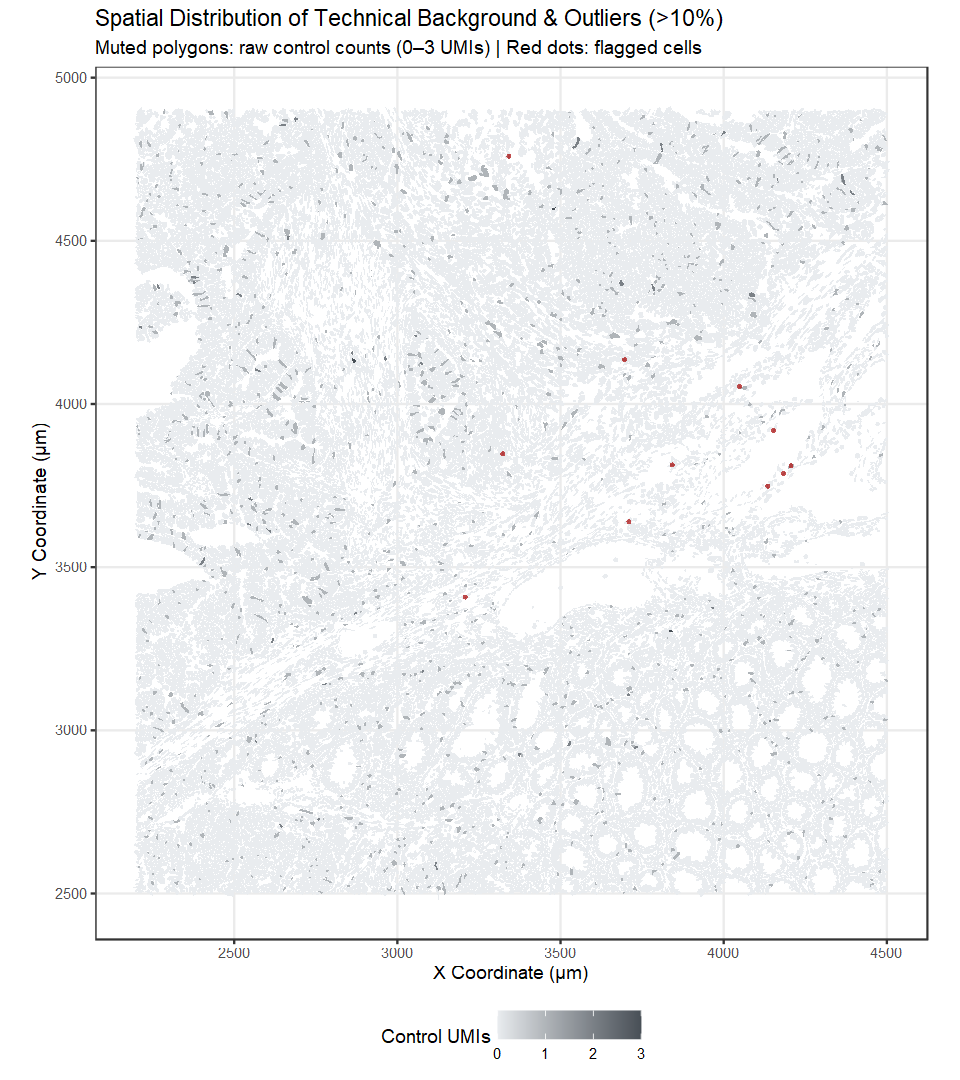

In [18]:
# Set canvas dimensions a little higher
options(repr.plot.width = 8, repr.plot.height = 9)

# Plot cell polygons colored by raw background counts, overlaying flagged centroids
plotSpatialFeature(
  sfe, 
  features        = "subsets_any_neg_sum", 
  colGeometryName = "cellSeg", 
  show_axes       = TRUE
) +
  scale_fill_gradient(
    low   = "#e9ecef", 
    high  = "#495057", 
    name  = "Control UMIs", 
    breaks = c(0, 1, 2, 3)
  ) +
  geom_sf(
    data  = flagged_centroids_10pct, 
    color = "firebrick", 
    size  = 0.8, 
    shape = 16, 
    alpha = 0.8
  ) +
  labs(
    title    = "Spatial Distribution of Technical Background & Outliers (>10%)",
    subtitle = "Muted polygons: raw control counts (0–3 UMIs) | Red dots: flagged cells", 
    x = "X Coordinate (µm)", 
    y = "Y Coordinate (µm)"
  ) +
  theme(legend.position = "bottom")

Inspecting the underlying polygon shading reveals that the vast majority of cells are pale gray (0 control UMIs). The rare cells capturing 1–3 control UMIs (darker gray specks) are sparsely and stochastically dispersed across the slide, confirming no localized optical flare or probe precipitation.

Crucially, zooming in shows that cells with the highest absolute control counts (2–3 UMIs, dark gray) rarely coincide with the red outlier flags (> 10%). Because those cells sit in transcript-dense epithelium or active crypts, 2–3 control molecules represent less than 0.5% of their library. The red dots instead pinpoint low-complexity stromal segments where just 1 solitary stray UMI inflates the ratio.

The flagged cells appear as isolated events rather than localized technical defects (no stitching seams, bubbles, or wash pools). While this rules out catastrophic failure, 10% remains very permissive. To test whether subtler gradients or autofluorescent patches emerge, we tighten our screen to a _stringent 3% threshold_ (`subsets_any_neg_percent > 3`).

In [19]:
# Flag cells exceeding the 3% technical background threshold
sfe[["flag_high_neg_3pct"]] <- (
  # Ensures pure boolean: !is.na(NaN) yields FALSE, preventing ghost NA rows in sf
  !is.na(sfe[["subsets_any_neg_percent"]]) & 
  sfe[["subsets_any_neg_percent"]] > 3
)

# Count how many cells are flagged at this threshold
n_flagged_3pct   <- sum(sfe[["flag_high_neg_3pct"]])
pct_flagged_3pct <- mean(sfe[["flag_high_neg_3pct"]]) * 100

cat(
  sprintf(
    "Flagged (>3%%): %d cells (%.2f%%)\n", n_flagged_3pct, pct_flagged_3pct))

Flagged (>3%): 50 cells (0.10%)


Tightening the cutoff to 3% flags only **50 cells (0.10%)**, confirming that over 99.9% of the dataset operates with negligible background. Mapping these 50 cells tests whether this low-level signal reveals subtle regional gradients or remains purely stochastic.

In [20]:
# Extract centroids of flagged cells for spatial overlay
flagged_centroids_3pct <- centroids(sfe)[sfe[["flag_high_neg_3pct"]], ]

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


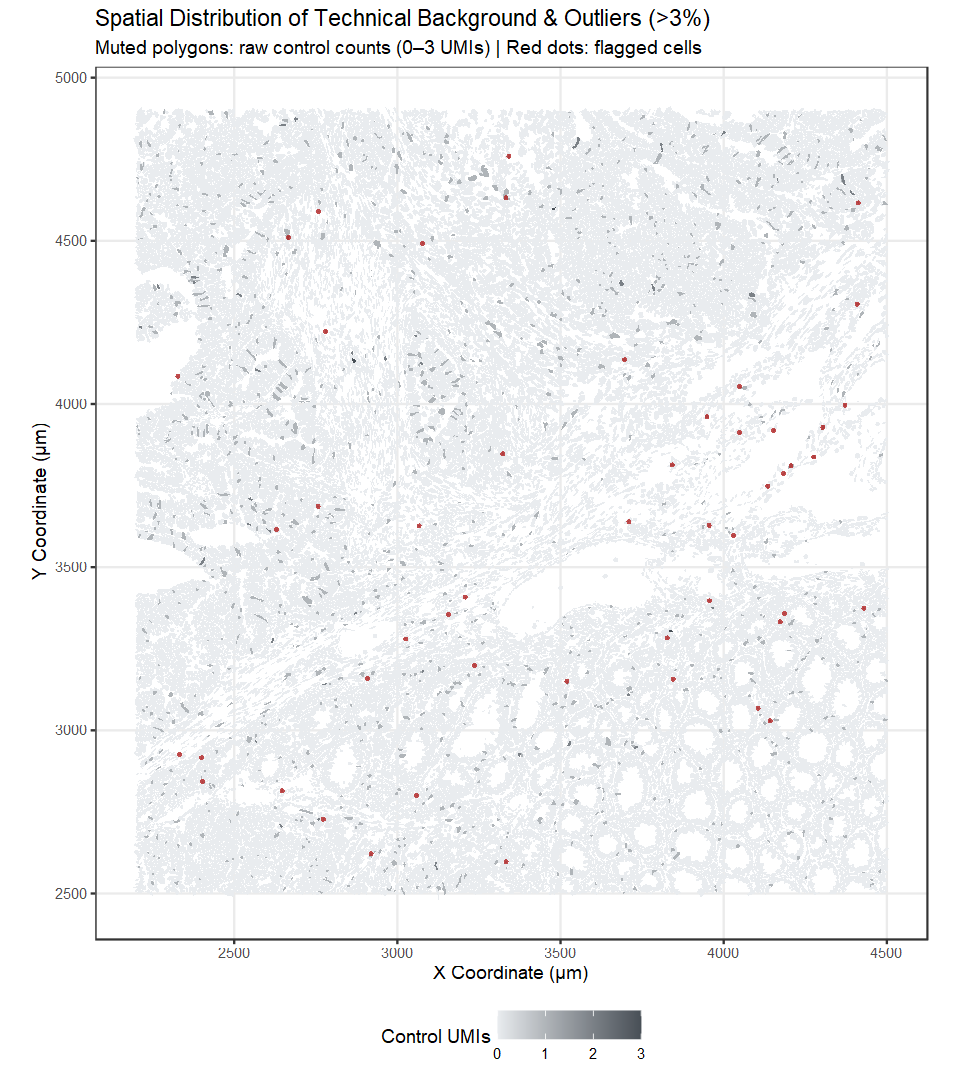

In [21]:
# Plot cell polygons colored by raw background counts, overlaying flagged centroids
plotSpatialFeature(
  sfe, 
  features        = "subsets_any_neg_sum", 
  colGeometryName = "cellSeg", 
  show_axes       = TRUE
) +
  scale_fill_gradient(
    low   = "#e9ecef", 
    high  = "#495057", 
    name  = "Control UMIs", 
    breaks = c(0, 1, 2, 3)
  ) +
  geom_sf(
    data  = flagged_centroids_3pct, 
    color = "firebrick", 
    size  = 0.8, 
    shape = 16, 
    alpha = 0.8
  ) +
  labs(
    title    = "Spatial Distribution of Technical Background & Outliers (>3%)",
    subtitle = "Muted polygons: raw control counts (0–3 UMIs) | Red dots: flagged cells", 
    x = "X Coordinate (µm)", 
    y = "Y Coordinate (µm)"
  ) +
  theme(legend.position = "bottom")

Even at a strict 3% threshold, the flagged cells remain isolated points without forming field-of-view stitching seams, optical defocus bands, or fluidic wash gradients across the slide.

The outliers preferentially track the interstitial spaces, lamina propria, and fibrous submucosa rather than the high-density epithelial crypts or invasive tumor nests. In these transcript-sparse niches, single stray molecules push the percentage past 3% without reflecting true probe contamination.

The technical background is spatially uniform Poisson noise. Because there are no defective optical tiles or corrupted tissue zones, **no regional spatial pruning is required**; these rare low-complexity profiles can be handled cleanly through single-cell library size filtering.

#### Cellular-scale density mapping (15-µm micro-bins)

Binning cell-assigned negative controls at **15-µm resolution** (approximating single-cell diameter) allows us to examine the spatial density of technical background without the multi-megabyte overhead of raw photon tables. By aggregating counts into physical micro-bins across the section, we can test whether background noise correlates with tissue density or reveals subtle optical seams.

In [22]:
# Extract coordinates and negative control counts into a lightweight data frame
df_neg_spatial <- data.frame(
  x = spatialCoords(sfe)[, 1],
  y = spatialCoords(sfe)[, 2],
  neg_count = sfe[["subsets_any_neg_sum"]]
)

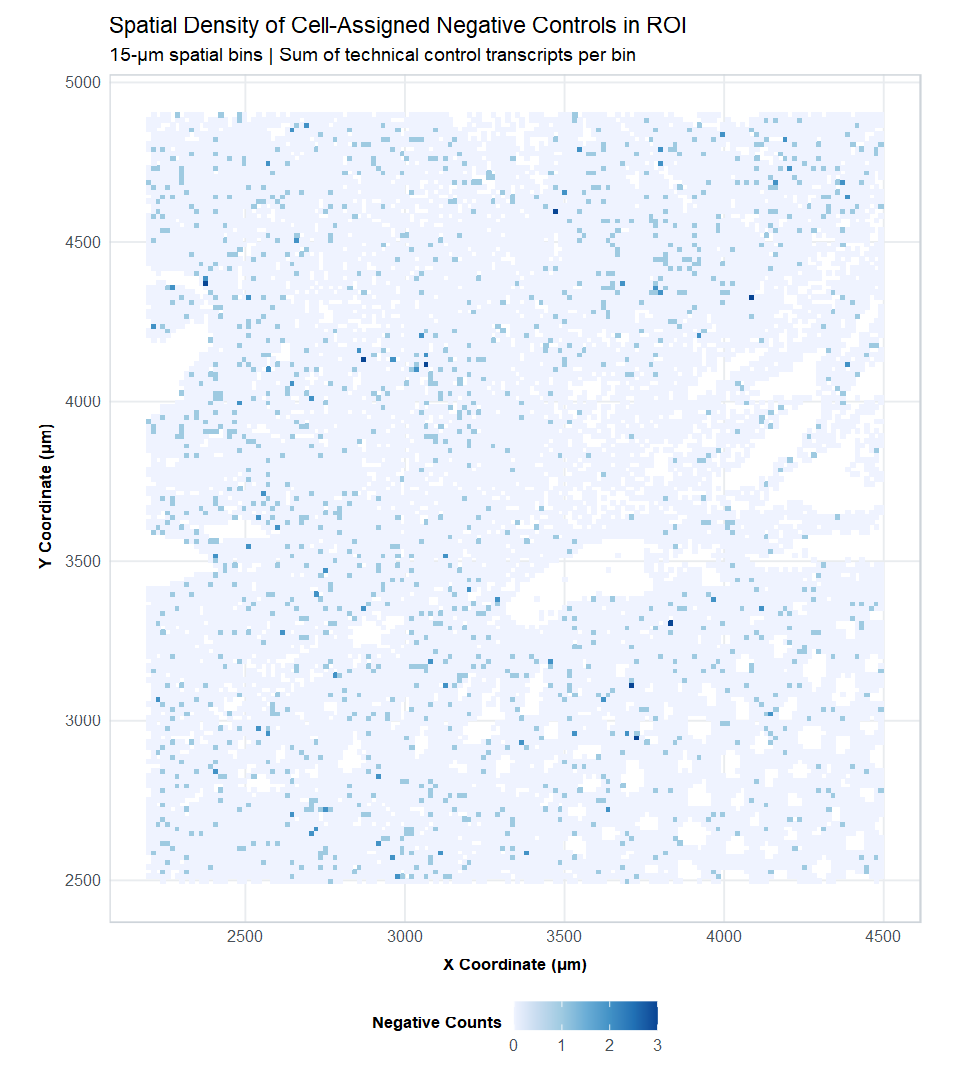

In [23]:
# Plot binned spatial density of cell-assigned negative control transcripts
ggplot(df_neg_spatial, aes(x = x, y = y, z = neg_count)) +
  stat_summary_2d(
    fun       = "sum", 
    binwidth  = 15
  ) +
  scale_fill_distiller(
    palette   = "Blues", 
    direction = 1, 
    name      = "Negative Counts"
  ) +
  coord_equal() +
  labs(
    title     = "Spatial Density of Cell-Assigned Negative Controls in ROI", 
    subtitle  = "15-µm spatial bins | Sum of technical control transcripts per bin", 
    x         = "X Coordinate (µm)", 
    y         = "Y Coordinate (µm)"
  ) +
  theme(legend.position = "bottom")

Acellular regions, such as empty crypt lumens (Y ∈ [2500, 3200]), vascular channels, and the left-margin tear, appear as clean white voids, while the vast majority of tissue bins remain near zero (pale blue).

The rare darker blue bins (2–3 UMIs) coincide with densely packed epithelial crypt walls and tumor cords. In these dense niches, higher concentrations of rolling-circle amplification products slightly increase the physical probability of minor probe entrapment or optical cross-talk.

Importantly, no straight borders, regular grid lines, or isolated off-tissue signals appear, ruling out field-of-view stitching seams or optical aberrations. This confirms the high fidelity of our colorectal ROI, allowing us to proceed to single-cell and morphological filtering.

> In full-scale primary runs, instrument operators often inspect raw `transcripts.parquet` files to verify that negative control molecules outline the physical tissue footprint rather than depositing on bare glass. Because raw transcript tables span tens of gigabytes, they were omitted during our cropped ROI assembly ([Notebook 00](./00-assembling_spatial_transcriptomics_datasets.ipynb)). Our cell-level spatial screen already definitively proves that technical background is negligible and uniformly stochastic.

## Cell quality & transcriptional complexity

Having confirmed that optical noise and probe cross-hybridization are virtually absent, we now evaluate the quality of the segmented cells themselves.

When `scuttle::addPerCellQCMetrics()` computed `sum` and `detected`, it operated across all 541 panel channels—inadvertently including negative control probes and codewords. While technical controls contribute at most 1–3 counts per cell, rigorous downstream analysis requires that library size (`nCounts`) and gene complexity (`nGenes`) reflect strictly **endogenous biological transcripts** (our 422 human target genes).

### Panel-normalized metrics

Unlike whole-transcriptome sequencing platforms (e.g. Visium HD or standard scRNA-seq) where tens of thousands of genes are profiled, Xenium relies on targeted panels ranging from 50 to 5,000 targets. Consequently, raw counts and gene detection cannot be compared directly across different experiments or published studies.

To establish cross-study comparability, we calculate **panel-normalized** metrics:

$$
n_\texttt{counts\_normed} = \frac{n_\text{counts}}{N_{\text{panel}}}, \quad n_\texttt{genes\_normed} = \frac{n_\text{genes}}{N_{\text{panel}}}
$$

where:

- $N_{\text{panel}} = 422$ is the number of biological targets
- $n_\texttt{counts\_normed}$ measures the average number of transcripts captured per targeted gene channel
- $n_\texttt{genes\_normed}$ represents the exact fraction of the panel detected in an individual cell (ranging between $0.0$ and $1.0$).

In [24]:
# Identify strictly biological target genes
is_bio <- rowData(sfe)[["Type"]] == "Gene Expression"
n_panel <- sum(is_bio)

cat(sprintf("Biological panel targets: %d genes\n", n_panel))

# Recompute endogenous library size and detected genes
counts_bio <- counts(sfe)[is_bio, ]

sfe[["nCounts"]] <- colSums(counts_bio)
sfe[["nGenes"]]  <- colSums(counts_bio > 0)

# Compute panel-normalized metrics
sfe[["nCounts_normed"]] <- sfe[["nCounts"]] / n_panel
sfe[["nGenes_normed"]]  <- sfe[["nGenes"]] / n_panel

# Preview the newly appended metrics for the first few cells
colData(sfe)[1:5, c("nCounts", "nGenes", "nCounts_normed", "nGenes_normed")]

Biological panel targets: 422 genes


DataFrame with 5 rows and 4 columns
             nCounts    nGenes nCounts_normed nGenes_normed
           <numeric> <integer>      <numeric>     <numeric>
ablhnkec-1       116        55       0.274882     0.1303318
ablhpkkh-1       120        41       0.284360     0.0971564
ablicbjh-1        89        48       0.210900     0.1137441
ablilfnl-1        81        43       0.191943     0.1018957
ablineen-1       145        57       0.343602     0.1350711

### Transcriptional complexity distributions

Because targeted panels operate within a bounded gene set (422 targets), cellular yields span a much narrower dynamic range (0–1500 UMIs) than genome-wide sequencing assays (10^1–10^5 UMIs). Consequently, viable cells and low-yield stromal fragments merge along a continuous distribution rather than forming distinct droplet peaks.

While extreme multi-decade sequencing data demands a logarithmic scale, targeted yields are effectively visualized on a **linear scale**. This preserves the physical shape of the distribution, clearly exposing the mode where typical stromal/mucosal cells reside (≈50–100 counts) and the long rightward tail of hyperactive tumor cells.

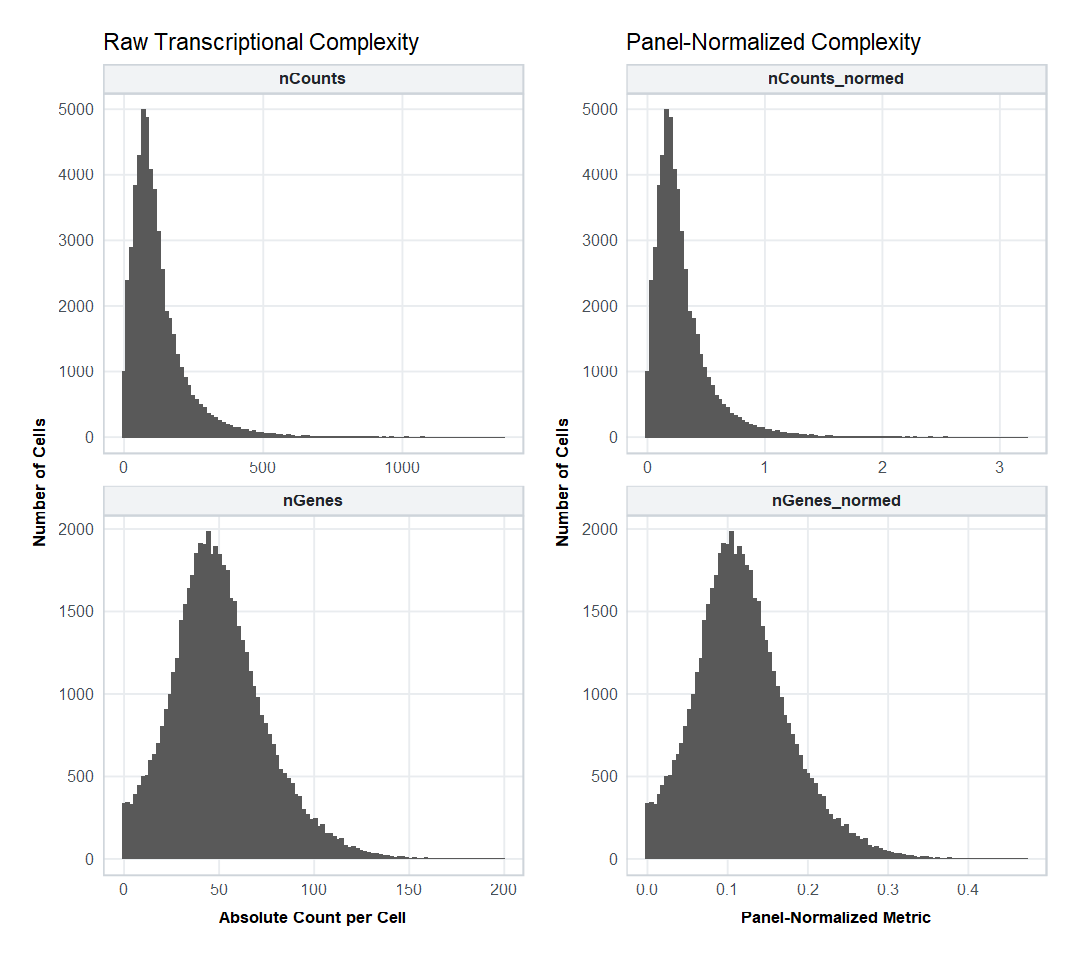

In [25]:
# Set canvas dimensions
options(repr.plot.width = 9, repr.plot.height = 8)

# Raw count and gene complexity histograms
p_raw <- plotColDataHistogram(
  sfe, 
  feature = c("nCounts", "nGenes"), 
  bins    = 100
) +
  labs(
    title = "Raw Transcriptional Complexity", 
    x     = "Absolute Count per Cell", 
    y     = "Number of Cells"
  )

# Panel-normalized complexity histograms
p_normed <- plotColDataHistogram(
  sfe, 
  feature = c("nCounts_normed", "nGenes_normed"), 
  bins    = 100
) +
  labs(
    title = "Panel-Normalized Complexity", 
    x     = "Panel-Normalized Metric", 
    y     = "Number of Cells"
  )

# Combine side-by-side using patchwork
p_raw | p_normed

Visual inspection of the histograms reveals that biological transcript counts (`nCounts`) peak near ≈80–100 UMIs per cell (_the Xenium Analysis Summary indicates a median transcripts per cells of 94 for the full slide_) before decaying in a classic right-skewed distribution. A long tail extends past 500 to over 1,000 transcripts, reflecting transcriptionally hyperactive adenocarcinoma cells. In contrast, gene diversity (`nGenes`) follows a remarkably symmetric, bell-shaped distribution centered near ≈50 genes, indicating that most viable cells express a consistent baseline repertoire of housekeeping and lineage markers.

On a panel-normalized scale, typical cells capture ≈10–12% of the panel (`nGenes_normed`), while high-yield epithelial cells detect upwards of 30–35% of the 422 targets. Crucially, the distribution rises sharply from the origin without forming a secondary low-count peak or an exaggerated zero spike, confirming that optical segmentation predominantly captured viable cellular RNA rather than empty acellular debris.

> Because `nCounts_normed` is simply raw library size divided by 422, its distribution shape is identical to `nCounts`. Its scale reveals that cells average ≈0.2 transcripts per targeted gene channel (reaching 1–3 in dense tumor cells), providing a standardized metric of capture density that can be compared directly across panels of different sizes.

### Spatial mapping of cellular yields

Evaluating transcriptional yield purely from histograms ignores spatial context. A low-count cell in an imaging assay can reflect two fundamentally different scenarios:

1. **Technical dropout:** Poor optical permeabilization, localized focal drift, or tissue detachment.
2. **Biological quiescence:** Naturally low-complexity tissue microenvironments, such as collagenous ECM, quiescent fibroblasts, or anucleate vascular lumens.

> While a linear axis faithfully displays the 1D frequency mode in a histogram, applying a linear color gradient to physical polygons causes a few hyper-expressing tumor cells (> 800 UMIs) to monopolize the entire warm spectrum. This would crush 95% of the tissue (cells with 20–200 UMIs) into an indistinguishable dark blue smear. Applying `trans = "log10"` to `nCounts` expands visual dynamic range, allowing us to distinguish quiescent stroma (deep blue) from mucosal crypts (green/yellow) and invasive adenocarcinoma (red). For `nGenes`, whose distribution is already symmetric, a linear scale works out of the box.

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


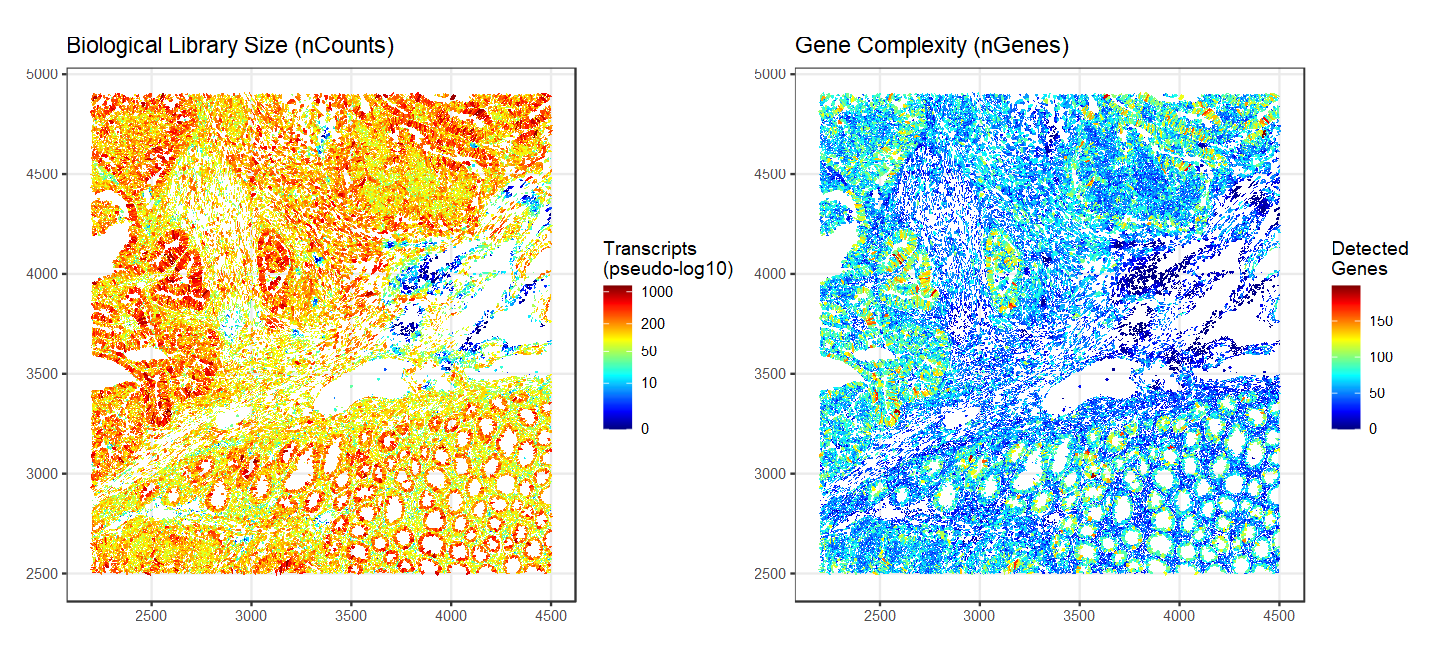

In [26]:
# Set canvas dimensions for dual spatial maps
options(repr.plot.width = 12, repr.plot.height = 5.5)

# Generate spatial polygon maps for library size and gene diversity
p_spatial_counts <- plotSpatialFeature(
  sfe, 
  features        = "nCounts", 
  colGeometryName = "cellSeg",
  show_axes       = TRUE
) +
  scale_fill_gradientn(
    colors = pals::jet(), 
    trans  = scales::pseudo_log_trans(base = 10, sigma = 1), 
    breaks = c(0, 10, 50, 200, 1000),
    name   = "Transcripts\n(pseudo-log10)"
  ) +
  labs(title = "Biological Library Size (nCounts)") +
  theme(legend.position = "right")


p_spatial_genes <- plotSpatialFeature(
  sfe, 
  features        = "nGenes", 
  colGeometryName = "cellSeg", 
  show_axes       = TRUE
) +
  scale_fill_gradientn(
    colors = pals::jet(), 
    name   = "Detected\nGenes"
  ) +
  labs(title = "Gene Complexity (nGenes)") +
  theme(legend.position = "right")

# Display side-by-side
p_spatial_counts | p_spatial_genes

Comparing the spatial maps directly to our 3D histopathological model of Patient P2 _(accounting for the vertical orientation flip in Xenium's Cartesian micron coordinates relative to standard H&E image pixels)_ confirms that variations in cellular yield mirror authentic tissue architecture rather than technical dropouts.

<img src="../assets/img/CRC_histology_3D_representation.png" 
     alt="3D schematic representation of colorectal adenocarcinoma tissue compartments" 
     style="width: 6in; max-width: 100%; display: block; margin: 1rem auto;">

At the bottom (Y ∈ [2500, 3200]), **normal mucosa** exhibits well-organized epithelial crypt rings with _moderate, uniform yields_ (≈100–300 counts, 50–70 genes) encircling empty lumens. The **central submucosa** displays _lower basal transcription_ (≈20–50 counts) while cleanly delineating an acellular dilated vessel (X ∈ [3200, 3700]), and the _focal deep-blue patch_ in the mid-right (X ∈ [3800, 4200]) captures naturally **quiescent, compact lymphocytes** (<15 counts, <20 genes). In sharp contrast, the **invasive adenocarcinoma** across the top and left (Y ∈ [3700, 5000]) drives _extreme transcriptional hyperactivation_ (>500 to >1,000 counts, warm red/orange).

This spatial architecture directly explains the distribution shapes observed in our earlier histograms. The long rightward tail in `nCounts` is driven exclusively by the metabolically hyperactive malignant tumor nests. Conversely, the symmetric bell curve in `nGenes` (peaking at ≈48–50 genes) reflects a stable baseline of shared housekeeping and structural transcripts expressed across mucosa and stroma, with even hyperactive adenocarcinoma cells plateauing near ≈100–140 genes due to the saturation of our targeted 422-plex panel.

### Bivariate library complexity (`nCounts` vs. `nGenes`)

In a healthy spatial assay, library size and gene diversity should follow a tightly coupled, monotonic curve. As a cell captures more transcripts, it progressively discovers more unique genes in the panel, with the curve flattening slightly at high counts as it approaches panel saturation ($N_{\text{panel}} = 422$).

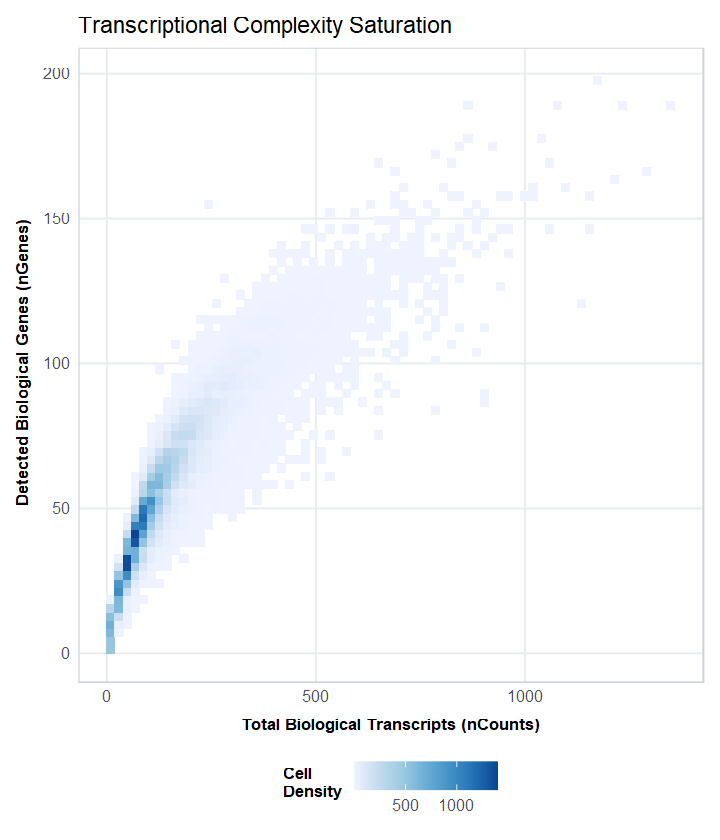

In [27]:
# Set canvas dimensions for bivariate density plot
options(repr.plot.width = 6, repr.plot.height = 7)

# Extract strictly the relevant QC columns
df_complexity <- as.data.frame(colData(sfe)[, c("nCounts", "nGenes")])

# Plot bivariate 2D density with hexagonal/square binning
ggplot(df_complexity, aes(x = nCounts, y = nGenes)) +
  geom_bin2d(bins = 70) +
  scale_fill_distiller(
    palette   = "Blues", 
    direction = 1, 
    name      = "Cell\nDensity"
  ) +
  labs(
    title    = "Transcriptional Complexity Saturation",
    x        = "Total Biological Transcripts (nCounts)",
    y        = "Detected Biological Genes (nGenes)"
  ) +
  theme(legend.position = "bottom")

Cells follow a smooth, unified trajectory. At low library sizes (`nCounts` <100), the slope is steep as each newly captured transcript discovers a new gene. Beyond ≈200–300 transcripts, the curve bends toward a plateau near 120–160 genes as the targeted 422-plex panel progressively saturates.

Moreover, the complete absence of bottom-right outliers (cells with high counts but few genes) rules out probe crystallization, optical flare, or single runaway transcripts. Instead, the cells form a single, continuous density ridge, confirming consistent detection efficiency across both low-yield stroma and hyperactive adenocarcinoma cells.

### Upstream transcript decoding quality (Q20 cut-off)

In imaging spatial transcriptomics, the primary instrument pipeline (`xenium-analyzer`) evaluates every optical signal using a Phred-scaled **Quality Value (`qv`)**:

$$
Q = -10 \log_{10}(P_{\text{error}})
$$

Just as in sequencing, **Q20 (Q = 20) represents 99% decoding confidence** (a 1% probability of false optical assignment). 

Inspecting the [Run Summary Report](../data/Human_Colon_Cancer_P2/reports/Xenium_V1_Human_Colon_Cancer_P2_CRC_Add_on_FFPE_analysis_summary.html) justifies this cutoff at both the molecule and gene levels:

- **Molecule-level quality distribution (`Transcript Quality` histogram):**  Negative control codewords and unassigned codewords decay rapidly as quality increases and drop to near-zero above Q = 20. In contrast, genuine biological transcripts peak decisively at the maximum score of **Q = 40 (> 10 million transcripts)**, confirming near-flawless cycle-by-cycle optical decoding for the vast majority of detected molecules.
- **Gene-level bimodal bifurcation (`Gene-Specific Transcript Quality` scatter plot):**  Aggregating quality per gene reveals a clean physical phase transition. Non-biological controls (negative codewords and unassigned targets) cluster tightly below Q < 16 and around 1000 transcript per gene, while predesigned and custom target genes cleanly separate into a high-quality cloud (Q ≈ 25–35; total transcripts per gene between 5000 and 1M). Setting the cutoff at **Q = 20** falls squarely in the valley between these two populations, purging optical miscalls without sacrificing real biological signal.

Across the entire slide, **50,594,830 high-quality transcripts** were decoded, with **76.6% exceeding Q ≥ 20** and **83.2% successfully assigned into cell polygons**. Crucially, the **Mean Q-score Spatial Map** confirms that the slide interior operates uniformly at near-maximum optical fidelity (Q ≈ 35–40, deep purple; > 99.95% accuracy), with lower scores confined to outer tissue tears.

Because 10x Genomics automatically drops low-confidence calls (Q < 20) when constructing `cell_feature_matrix.h5`, our loaded `sfe` object already exclusively contains verified, high-confidence cellular transcripts.

## Cell segmentation & morphological QC

In sequencing-based spatial transcriptomics (Visium HD), spatial bins are defined by a rigid, deterministic physical grid (e.g. 16-µm or 2-µm squares). In imaging-based platforms (Xenium), single-cell boundaries do not physically exist on the slide—they must be **optically inferred from high-resolution fluorescence microscopy**.

Cell segmentation is a high-stakes analytical step in _in situ_ spatial biology:

- **Under-segmentation (merging):** If optical boundaries fail to separate touching cells, multiple distinct neighbors are fused into an artificial chimeric polygon, contaminating cell-type signatures and inflating library sizes.
- **Over-segmentation (splitting):** If a single large cell is erroneously fractured into multiple fragments, transcripts are artificially dispersed, creating spurious low-count "cells" lacking nuclei.
- **Acellular noise capture:** In acellular extracellular matrix (ECM) or fluid-filled cavities, spurious boundaries can enclose isolated stray transcripts.

### Multimodal optical segmentation in Xenium

Rather than relying solely on arbitrary circular expansions around DAPI nuclei, the Xenium Analyzer employs deep-learning segmentation models trained on the [**Xenium Multi-Tissue Stain** (`xenium_cell_segmentation_stains_v1`)](https://www.10xgenomics.com/support/jp/software/xenium-onboard-analysis/latest/algorithms-overview/segmentation#seg-multimodal). This cocktail stains both physical cell membranes (boundary stain) and intracellular RNA (interior stain) in addition to DAPI nuclear counterstains.

As documented in the [Run Summary Report](../data/Human_Colon_Cancer_P2/reports/Xenium_V1_Human_Colon_Cancer_P2_CRC_Add_on_FFPE_analysis_summary.html) and `metrics_summary.csv`:

| Segmentation Method | Cell Count | Fraction | Methodological Role |
| :--- | :---: | :---: | :--- |
| **Cells segmented by interior RNA stain** | 246,366 | 72.3% | Boundaries inferred from intracellular cytoplasmic RNA stain. |
| **Cells segmented by boundary stain** | 85,170 | 25.0% | Boundaries delineated by physical cell membrane proteins. |
| **Cells segmented by nucleus expansion (5.0 µm)** | 9,301 | 2.7% | Fallback radial expansion where fluorescent stains were ambiguous. |
| **Total cells detected** | 340,837 | 100% | Full-slide cell total (our cropped ROI captures **52,569** cells). |

### Morphological QC metrics in SFE

In our ingested `sfe` object, optical segmentation yields two distinct geometric layers stored in `colGeometries(sfe)`: the whole-cell polygon (`cellSeg`) and the nuclear polygon (`nucSeg`). From these geometries, three primary morphological metrics are derived in `colData(sfe)`:

1. **Cell Area (`cell_area`, µm²):**  The two-dimensional cross-sectional area of the whole cell polygon. In human FFPE sections, typical viable cells peak near **≈ 30–60 µm²**, with a right-skewed tail extending to 200–400 µm² representing elongated stromal fibroblasts, large goblet cells, or hypertrophic carcinoma cells. Polygons below ≈ 10–15 µm² are implausibly small and typically represent over-segmentation debris.
2. **Nuclear Area (`nucleus_area`, µm²):**  The cross-sectional area of the DAPI-stained nuclear mask.
3. **Nuclear-to-Cell Ratio (`prop_nuc`):**  The fraction of cellular volume occupied by the nucleus (`prop_nuc` = `nucleus_area` / `cell_area`). Biophysically, a genuine segmented cell must obey 0 < `prop_nuc` ≤ 1.0. Ratios near 1.0 denote small lymphocytes with scant cytoplasm, while ratios near 0 or missing nuclei indicate anucleate cytoplasmic fragments or acellular background segments.

### Baseline cell size distribution across the full slide

In the [Run Summary Report](../data/Human_Colon_Cancer_P2/reports/Xenium_V1_Human_Colon_Cancer_P2_CRC_Add_on_FFPE_analysis_summary.html), the **Cell Size Distribution** histogram establishes the global morphological baseline for all 340,837 segmented cells:

- **Modal cross-sectional area (≈ 40–50 µm²):** The distribution peaks sharply near **≈ 40–50 µm²** (with nearly 25,000 cells in the modal bin). In a 5-µm FFPE tissue slice, this area corresponds to the typical planar cross-section of viable human colonic epithelial cells and infiltrating lymphocytes (diameters of ≈ 7–9 µm).
- **Steep lower truncation (< 15–20 µm²):** The frequency plunges precipitously below ≈ 15 µm². Because a healthy human diploid nucleus physically occupies at least 15–20 µm² in cross-section, polygons smaller than this floor represent acellular debris or over-segmentation fragments.
- **Extended right-skewed tail (> 150–300 µm²):** The distribution displays a long, smooth tail stretching past 150 to over 300 µm² (with rare events reaching 600 µm²). Biologically, this tail captures large hypertrophic adenocarcinoma cells, spread-out submucosal fibroblasts, and mucin-distended goblet cells. However, it also harbors potential **under-segmentation artifacts** (adjacent cell boundaries failing to separate, creating chimeric doublets).

### Cell and nuclear cross-sectional areas

We now plot `cell_area` alongside `nucleus_area` for our 52,569 cells in `sfe`.

Warning message:
"Removed 3417 rows containing non-finite outside the scale range (`stat_bin()`)."


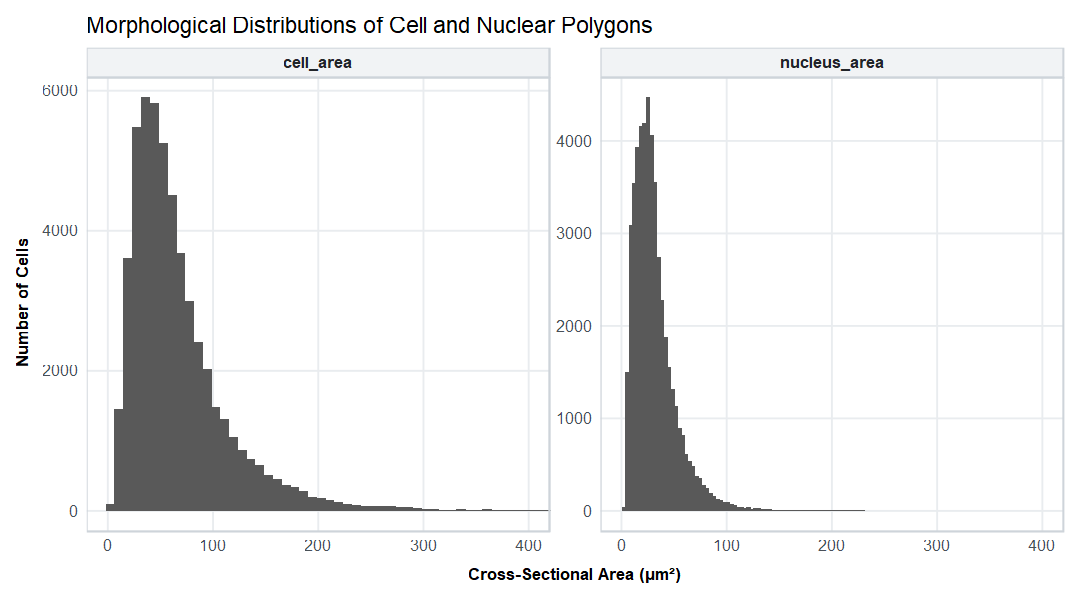

In [28]:
# Set canvas dimensions higher
options(repr.plot.width = 9, repr.plot.height = 5)

# Plot high-resolution histograms of cell and nuclear cross-sectional areas
plotColDataHistogram(
  sfe, 
  feature = c("cell_area", "nucleus_area"), 
  bins = 70,
  ncol =2
) +
  labs(
    title = "Morphological Distributions of Cell and Nuclear Polygons",
    x = "Cross-Sectional Area (µm²)",
    y = "Number of Cells"
  ) +
  coord_cartesian(xlim = c(0, 400))

Our cropped section faithfully reproduces the unimodal profile established in the instrument run report. Whole-cell area (`cell_area`) peaks sharply at **≈ 40–50 µm²**, matching the planar cross-section of viable human colonic epithelial cells and infiltrating lymphocytes in a 5-µm tissue slice. Nuclear area (`nucleus_area`) peaks cleanly to the left at **≈ 25–30 µm²**.

Moreover, the steep drop below ≈ 15 µm² confirms that over-segmentation debris is minimal, while the extended rightward tail out to 200–300+ µm² captures biologically authentic, enlarged adenocarcinoma cells and elongated submucosal fibroblasts alongside potential merged doublets.

### Spatial distribution and morphology of cell boundaries

#### Tissue-wide mapping of cellular and nuclear area

Because both metrics share the same physical units (µm²), our visual alignment confirms that nuclear masks sit strictly smaller than whole-cell boundaries across the entire population, with the DAPI nucleus averaging roughly half of the cellular cross-section. 

However, 1D frequency distributions cannot reveal whether size extremes are localized to specific histological compartments or reflect optical segmentation failure. For example, invasive adenocarcinoma cells are naturally enlarged and pleomorphic (high `cell_area`), lymphocytes possess minimal cytoplasm (small `cell_area`), and submucosal fibroblasts are spindly. On the other side, optical defocus, poor illumination, or tissue tears produce localized "hotspots" of implausibly giant merged polygons (under-segmentation) or dense fields of shattered polygon fragments (over-segmentation).

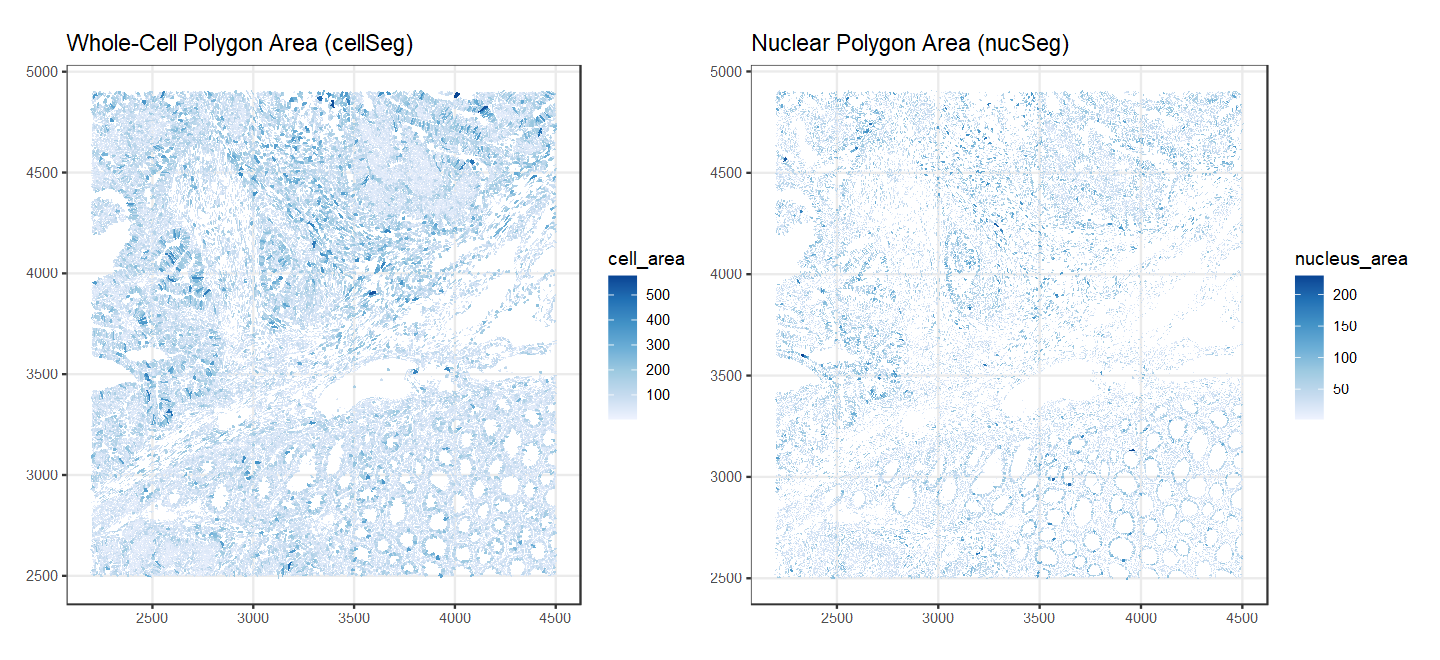

In [29]:
# Set canvas dimensions for side-by-side spatial maps
options(repr.plot.width = 12, repr.plot.height = 5.5)

# Map whole-cell area on cell polygons
p_cell_area <- plotSpatialFeature(
  sfe, 
  features        = "cell_area", 
  colGeometryName = "cellSeg", 
  show_axes       = TRUE
) +
  labs(title = "Whole-Cell Polygon Area (cellSeg)") +
  theme(legend.position = "right")

# Map nuclear area on nuclear polygons
p_nuc_area <- plotSpatialFeature(
  sfe, 
  features        = "nucleus_area", 
  colGeometryName = "nucSeg", 
  show_axes       = TRUE
) +
  labs(title = "Nuclear Polygon Area (nucSeg)") +
  theme(legend.position = "right")

# Combine side-by-side using patchwork
p_cell_area | p_nuc_area

#### Subcellular inspection of nested polygon wireframes

While macro spatial maps confirm that size distributions vary continuously across tissue compartments without large regional blowouts, verifying segmentation quality requires inspecting individual polygon wireframes at subcellular resolution.

We define a 400 × 400 µm bounding box (`roi_zoomed`) centered on the **submucosal invasive front** (X ∈ [3200, 3600], Y ∈ [3500, 3900]), right above the dilated blood vessel. In this interface, large neoplastic epithelial cords invade alongside slender fibroblasts and infiltrating immune cells, as we may remind from the previous notebooks.

In [30]:
# Define microscopic bounding box coordinates (submucosal invasive front)
roi_zoomed <- c(
  xmin = 3200,
  xmax = 3600,
  ymin = 3500,
  ymax = 3900)

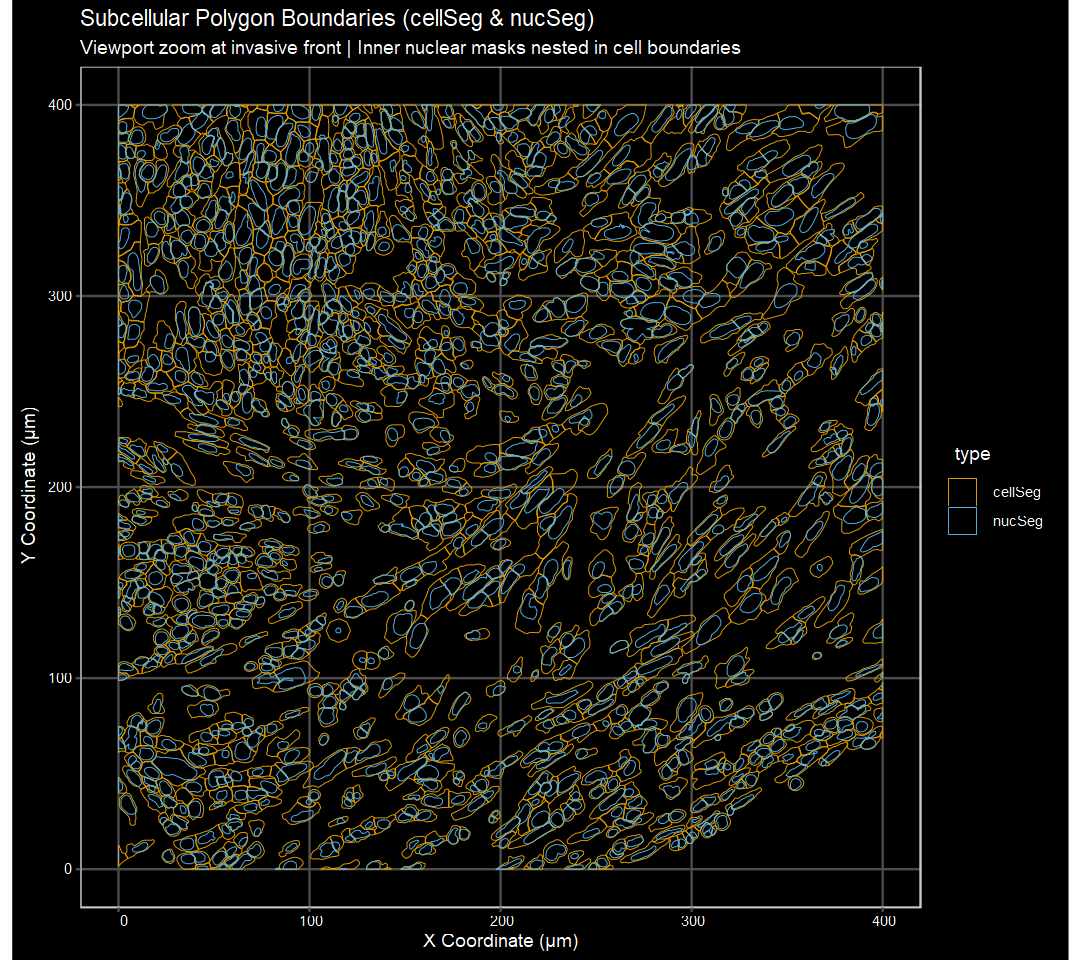

In [31]:
# Set canvas dimensions for zoomed wireframe inspection
options(repr.plot.width = 9, repr.plot.height = 8)

# Plot concentric cell and nuclear polygon boundaries
plotGeometry(
  sfe, 
  colGeometryName = c("cellSeg", "nucSeg"), 
  fill            = FALSE, # Renders crisp polygon outlines
  dark            = TRUE,  # Displays wireframes against a dark canvas
  show_axes       = TRUE, 
  bbox            = roi_zoomed
) +
  labs(
    title    = "Subcellular Polygon Boundaries (cellSeg & nucSeg)",
    subtitle = "Viewport zoom at invasive front | Inner nuclear masks nested in cell boundaries",
    x        = "X Coordinate (µm)",
    y        = "Y Coordinate (µm)"
  )

The cyan DAPI nuclear masks (`nucSeg`) nest cleanly inside the gold whole-cell boundaries (`cellSeg`), with virtually no overlapping boundaries between adjacent neighbors. Boundaries faithfully adapt to distinct cell types, capturing both tightly packed polygonal tumor nests (upper left) and elongated spindle-shaped fibroblasts (right).

#### Quantifying the nuclear-to-cell ratio (prop_nuc)

We must quantify this relationship across all 52,569 cells. The **nuclear-to-cell area ratio (`prop_nuc`)** provides a compact summary of segmentation balance:

$$
\texttt{prop\_nuc} = \frac{\texttt{nucleus\_area}}{\texttt{cell\_area}}
$$

In [32]:
# Compute the nuclear-to-cell area ratio using double-bracket accessors
sfe[["prop_nuc"]] <- sfe[["nucleus_area"]] / sfe[["cell_area"]]

Warning message:
"Removed 3417 rows containing non-finite outside the scale range (`stat_bin()`)."


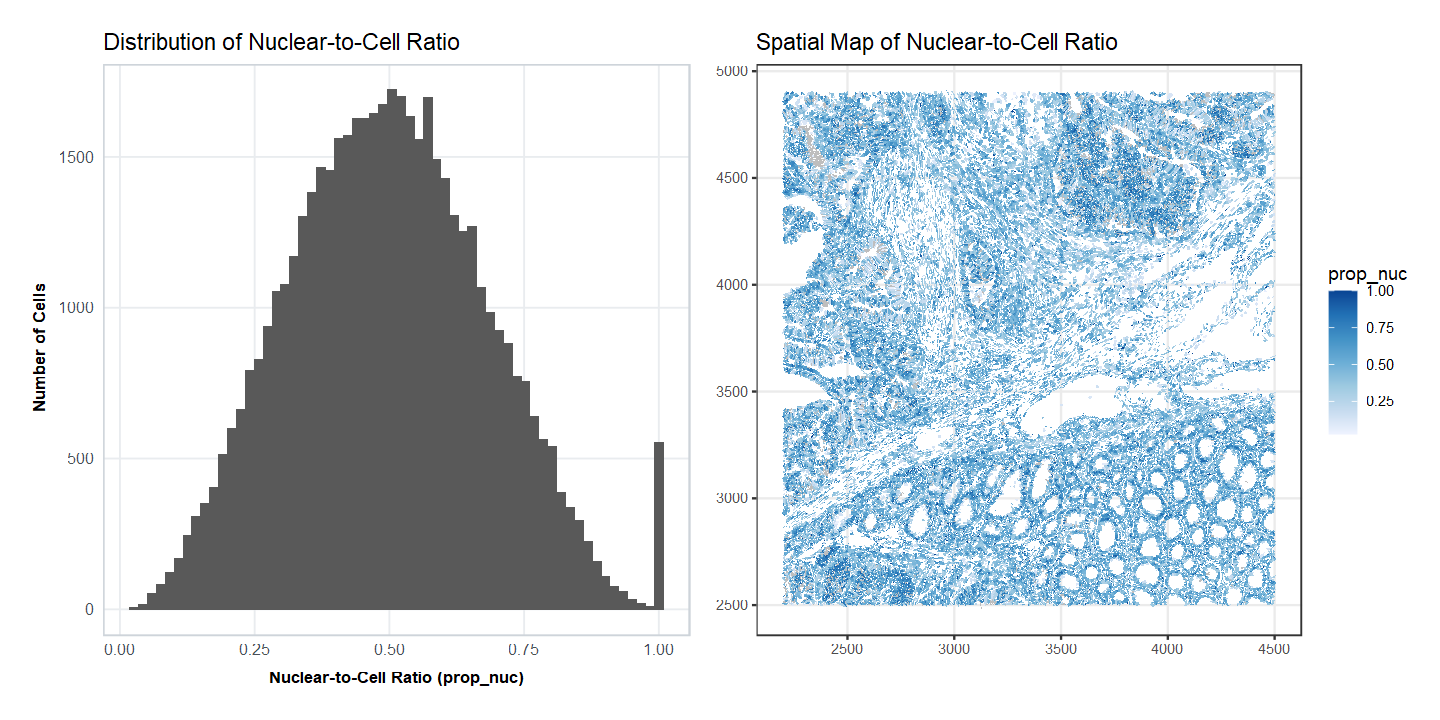

In [33]:
# Set canvas dimensions for side-by-side diagnostic panels
options(repr.plot.width = 12, repr.plot.height = 6)

# Distribution histogram
p_prop_hist <- plotColDataHistogram(sfe, feature = "prop_nuc", bins = 60) +
  labs(
    title    = "Distribution of Nuclear-to-Cell Ratio", 
    x        = "Nuclear-to-Cell Ratio (prop_nuc)",
    y        = "Number of Cells"
  )

# Spatial distribution map
p_prop_spatial <- plotSpatialFeature(
  sfe, 
  features        = "prop_nuc", 
  colGeometryName = "cellSeg", 
  show_axes       = TRUE
) +
  labs(
    title = "Spatial Map of Nuclear-to-Cell Ratio",
  ) +
  theme(legend.position = "right")


# Display side-by-side using patchwork
p_prop_hist | p_prop_spatial

The distribution (left panel) forms an approximately normal bell curve centered at ≈ 0.50, demonstrating that the nucleus typically occupies half of the total cellular cross-section. The vast majority of cells fall comfortably within a healthy morphological window (0.25–0.75).

A discrete spike of ≈ 550 cells (≈ 1%) sits at strictly `prop_nuc` = 1.0. These represent instances where the algorithm detected a DAPI nucleus but identified no surrounding cytoplasmic stain, defaulting to setting the cell boundary equal to the nuclear mask.

The spatial map (right panel) displays smooth, histology-driven variation. Elevated ratios (darker blue; better visualized when we zoom on the plot) naturally concentrate in the dense lymphoid aggregate (lymphocytes possess large nuclei and scant cytoplasm) and crowded tumor nests, while lower ratios (pale blue) characterize mucin-distended mucosal goblet cells and elongated submucosal fibroblasts.

### Pairwise correlation matrix of cell-level QC metrics

To synthesize our quality assessment, we evaluate all five cell-level metrics simultaneously (`nCounts`, `nGenes`, `cell_area`, `nucleus_area`, `prop_nuc`).

Warning message:
"Removed 47838 rows containing non-finite outside the scale range
(`stat_bin2d()`)."
Warning message:
"Removed 6834 rows containing non-finite outside the scale range
(`stat_autodensity()`)."


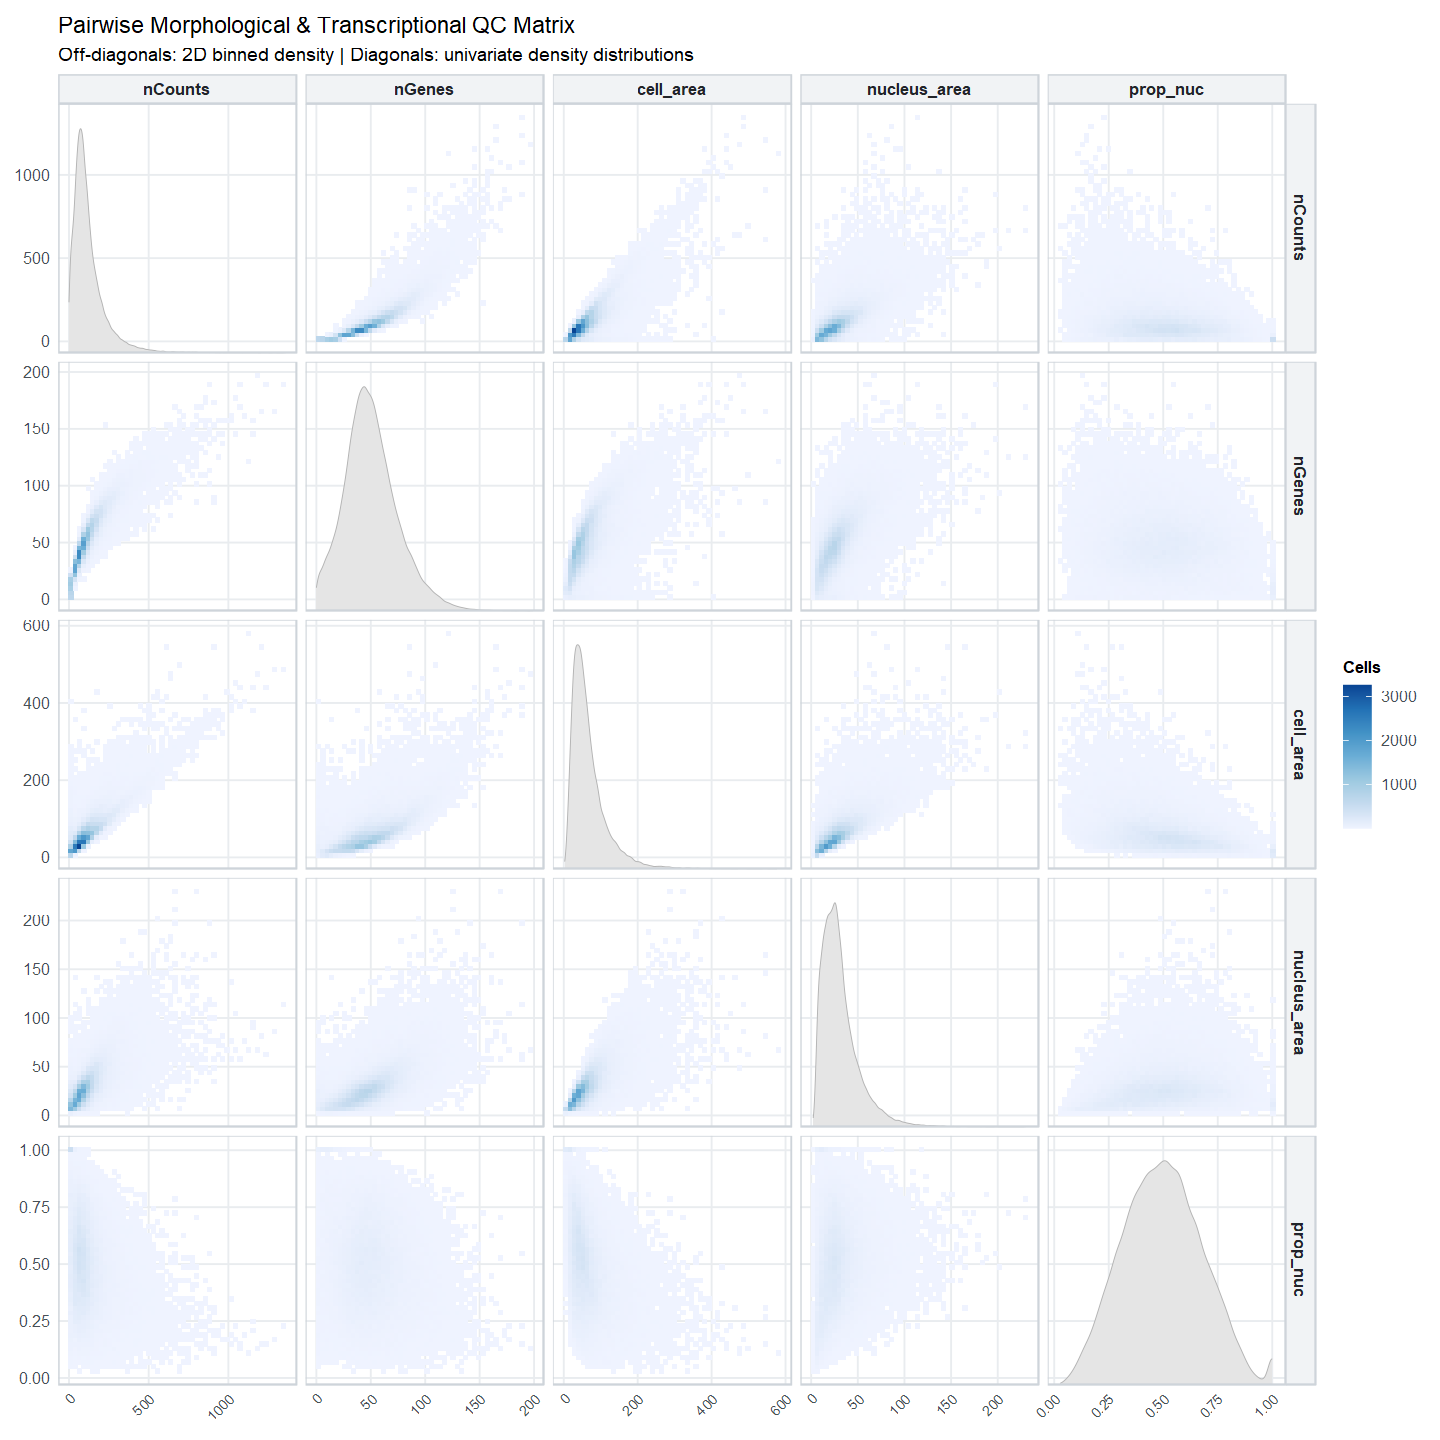

In [34]:
# Set canvas dimensions for the 5x5 pairwise matrix
options(repr.plot.width = 12, repr.plot.height = 12)

# Extract the five core cell QC metrics into a clean data frame
cols_use <- c("nCounts", "nGenes", "cell_area", "nucleus_area", "prop_nuc")
df_qc <- as.data.frame(colData(sfe)[, cols_use])

# Plot pairwise 2D binned density matrix with diagonal marginal densities
ggplot(df_qc) +
  geom_bin2d(aes(x = .panel_x, y = .panel_y), bins = 50) +
  geom_autodensity(fill = "gray90", color = "gray70", linewidth = 0.2) +
  facet_matrix(vars(tidyselect::everything()), layer.diag = 2) +
  scale_fill_distiller(palette = "Blues", direction = 1, name = "Cells") +
  labs(
    title    = "Pairwise Morphological & Transcriptional QC Matrix",
    subtitle = "Off-diagonals: 2D binned density | Diagonals: univariate density distributions"
  ) +
  theme(axis.text.x = element_text(size = 8, angle = 45, hjust = 1))

The 5 × 5 pairwise density matrix provides a comprehensive validation of cell-level assay mechanics, directly confirming key biological scaling relationships and the absence of joint artifacts.

1. **Verification of biological scaling relationships:**
   - **`cell_area` vs. `nCounts` (Row 1, Col 3):** Displays a strong, positive monotonic relationship. Larger cell polygons encompass greater cytoplasmic volume and naturally capture proportionally more mRNA transcripts (scaling smoothly from ≈ 50 UMIs in small lymphocytes to > 1,000 UMIs in hypertrophic tumor cells).
   - **`cell_area` vs. `nucleus_area` (Row 4, Col 3):** Nuclear size expands proportionally with cellular volume, remaining strictly bound beneath the identity line (`nucleus_area` ≤ `cell_area`).
   - **`cell_area` vs. `prop_nuc` (Row 5, Col 3):** Forms a characteristic triangular envelope. Only small, compact cells (area ≈ 20–50 µm², e.g. lymphocytes) exhibit elevated nuclear ratios (0.75–1.0). As cells expand in area (> 150 µm²), `prop_nuc` converges toward 0.25–0.45, reflecting abundant cytoplasmic accumulation.

2. **Absence of joint technical anomalies:**
   - **No optical bleed into fragments:** The upper-left corner of `cell_area` vs. `nCounts` is completely empty; there are no tiny polygons (< 20 µm²) capturing hundreds of transcripts, confirming that high yields are never driven by optical flare or probe crystallization on debris.
   - **No acellular ballooning:** The bottom-right corner of `cell_area` vs. `nCounts` is virtually clear; there are no giant polygons (> 300 µm²) with near-zero counts, confirming that segmentation boundaries did not artificially expand into empty extracellular space.
   - **Naked nuclei confinement:** The discrete spike at `prop_nuc` = 1.0 is restricted to low-count cells (`nCounts` < 50), reflecting minor membrane-staining dropouts on compact cells rather than large-scale segmentation failure.

### Evaluating anucleate cell segments

In our `sfe` object, optical segmentation identified a whole-cell polygon (`cellSeg`) for all 52,569 profiles, but a subset of cells has **no detected DAPI nucleus** (`is.na(nucleus_area)`).

In [35]:
# Flag cells with a detected DAPI nucleus
sfe[["has_nuclei"]] <- !is.na(sfe[["nucleus_area"]])

# Summary table of nucleated vs. anucleate segments
table(has_nuclei = sfe[["has_nuclei"]])

has_nuclei
FALSE  TRUE 
 3417 49152 

This phenomenon is primarily physical rather than an algorithmic failure. The measured optical transcript thickness across this sample is **6.42 µm** (Xenium Analysis Summary), matching a nominal 5-µm microtome slice. Because human colonic epithelial cells span 10–15 µm in diameter, a ≈ 6-µm slice inevitably cuts through the cytoplasm *above or below* the nuclear plane in a subset of cells, generating authentic cytoplasmic segments lacking a DAPI signal.

Additionally, detached cytoplasmic fragments, sectioning debris, or acellular mucus droplets can occasionally receive a segmentation boundary without enclosing genomic DNA.

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


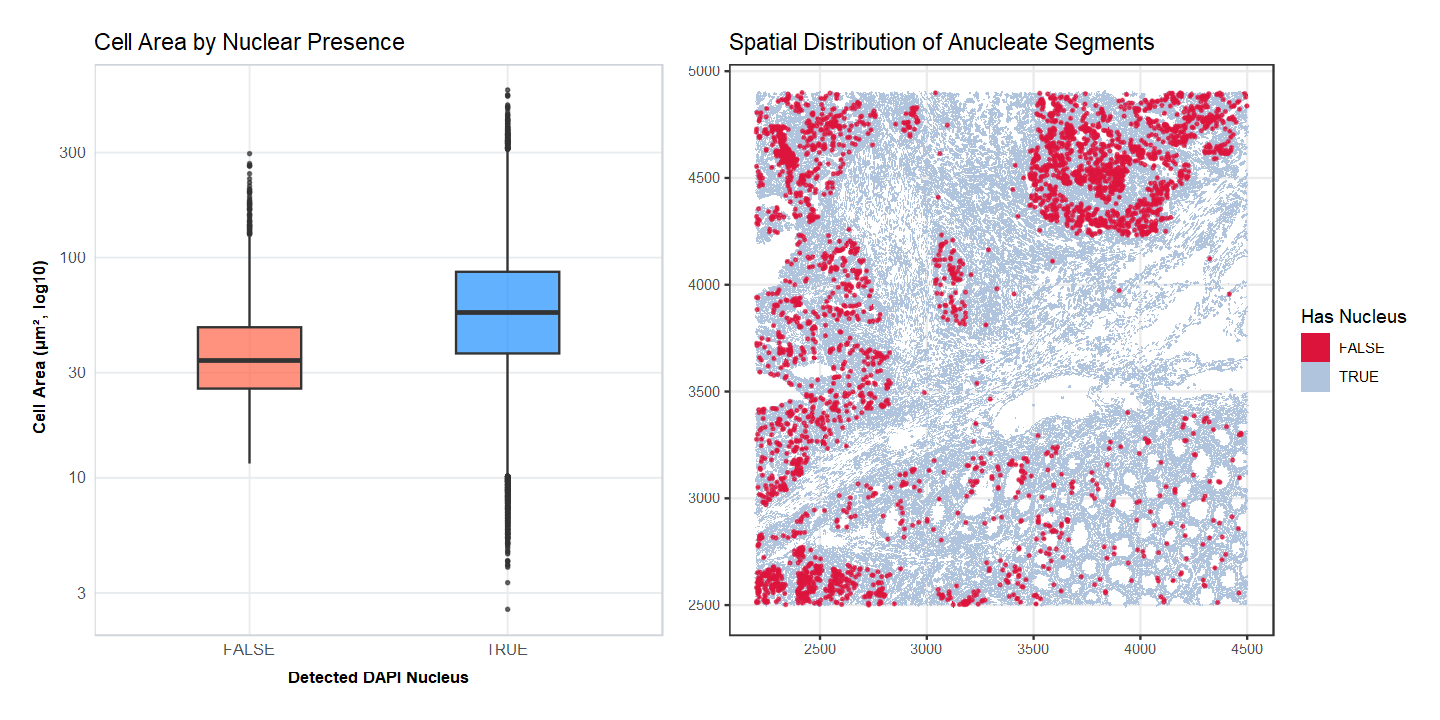

In [36]:
# Set canvas dimensions
options(repr.plot.width = 12, repr.plot.height = 6)

# Size comparison: anucleate cells are physically smaller cytoplasmic caps
p_nuc_size <- ggplot(
  as.data.frame(colData(sfe)), 
  aes(x = has_nuclei, y = cell_area, fill = has_nuclei)
) +
  geom_boxplot(outlier.size = 0.5, alpha = 0.7, width = 0.4) +
  scale_y_log10() +
  scale_fill_manual(
    values = c("FALSE" = "tomato", "TRUE" = "dodgerblue"), 
    name = "Has Nucleus"
  ) +
  labs(
    title = "Cell Area by Nuclear Presence",
    x = "Detected DAPI Nucleus",
    y = "Cell Area (µm², log10)"
  ) +
  theme(legend.position = "none")

# Spatial mapping: highlight anucleate centroids over the tissue
p_nuc_spatial <- plotSpatialFeature(
  sfe, 
  features = "has_nuclei", 
  colGeometryName = "cellSeg", 
  show_axes = TRUE
) +
  scale_fill_manual(
    values = c("FALSE" = "#dc143c", "TRUE" = "lightsteelblue"), 
    name   = "Has Nucleus"
  ) +
  geom_sf(
    data = centroids(sfe)[!sfe[["has_nuclei"]], ], 
    color = "#dc143c", 
    size = 0.4, 
    alpha = 0.7
  ) +
  labs(
    title = "Spatial Distribution of Anucleate Segments",
  ) +
  theme(legend.position = "right")

p_nuc_size | p_nuc_spatial

Anucleate segments (`has_nuclei = FALSE`; red) have a significantly smaller median area (≈ 35–40 µm²) compared to nucleated cells (≈ 60–70 µm²; blue). This confirms they primarily represent partial-thickness cytoplasmic caps sheared off during microtome slicing rather than fully expanded cells.

Moreover, rather than scattering randomly across the slide, anucleate segments concentrate predominantly within the **invasive adenocarcinoma** (top and upper-right), where crowded cell packing and irregular nuclear orientations increase the probability of off-center planar slicing. Conversely, they are rare in normal mucosa and virtually absent in the submucosa.

To inspect how these boundaries appear physically at subcellular resolution, we zoom into an anucleate-enriched tumor nest (X ∈ [3700, 3900], Y ∈ [4400, 4600]).

In [37]:
# Viewport coordinates centered on tumor nest with anucleate segments
roi_anucleate <- c(
  xmin = 3700, 
  xmax = 3900, 
  ymin = 4400, 
  ymax = 4600)

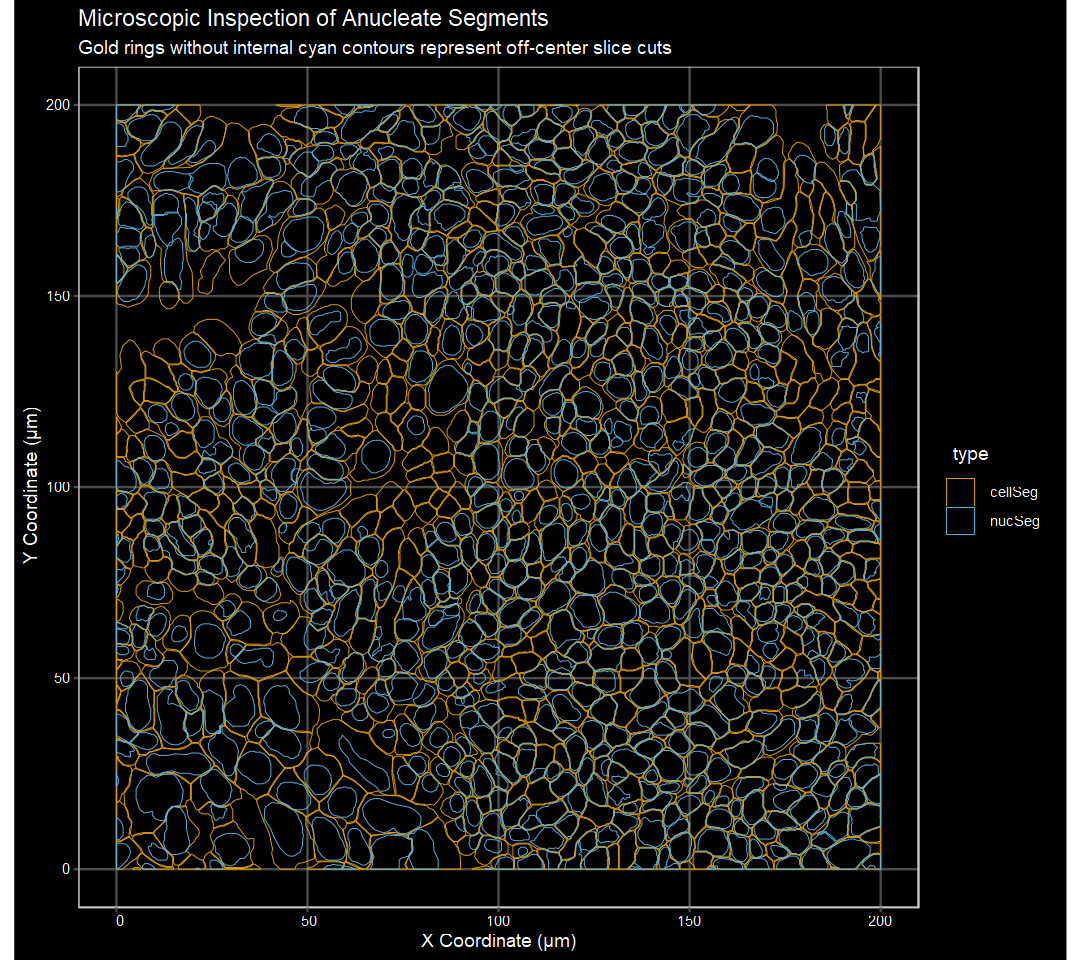

In [38]:
# Set canvas dimensions for zoomed wireframe inspection
options(repr.plot.width = 9, repr.plot.height = 8)

# Render wireframes: gold cell boundaries lacking cyan nuclei appear as empty rings
plotGeometry(
  sfe, 
  colGeometryName = c("cellSeg", "nucSeg"), 
  fill            = FALSE, 
  dark            = TRUE, 
  image_id        = NULL, 
  show_axes       = TRUE,
  bbox            = roi_anucleate
) +
  labs(
    title    = "Microscopic Inspection of Anucleate Segments", 
    subtitle = "Gold rings without internal cyan contours represent off-center slice cuts", 
    x        = "X Coordinate (µm)", 
    y        = "Y Coordinate (µm)"
  )

The anucleate segments (gold outlines without internal cyan nuclear contours, e.g. around coordinates X ≈ 75, Y ≈ 125) are not erratic, jagged artifacts. They possess regular, convex, polygonal boundaries that interlock seamlessly with their nucleated neighbors. These polygons represent authentic planar cuts through the apical or basal cytoplasm of genuine cells whose nuclei resided in the adjacent physical microtome slice.

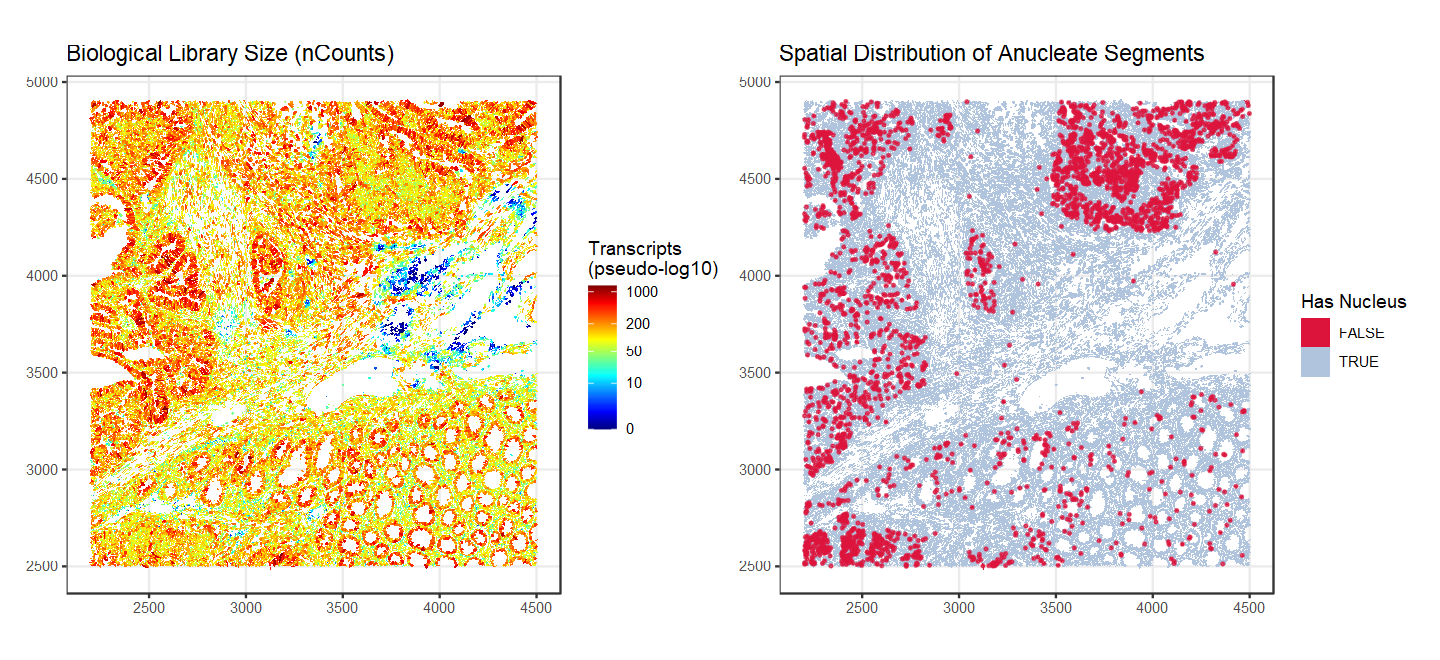

In [39]:
# Set canvas dimensions for side-by-side visual cross-reference
options(repr.plot.width = 12, repr.plot.height = 5.5)

# Visual comparison: Transcriptional yields vs. Anucleate cell locations
p_spatial_counts | p_nuc_spatial

Cross-referencing our `has_nuclei` spatial map with our earlier `nCounts` spatial map confirms that anucleate segments concentrate within the transcriptionally hyperactive adenocarcinoma compartment, retaining substantial cytoplasmic mRNA. Because these profiles represent viable tissue rather than empty debris, **lacking a DAPI nucleus is not an automatic ground for exclusion**. They should only be filtered if they independently fail minimum library size or area thresholds!

### Intracellular transcript density

In our earlier 5 × 5 pairwise matrix, we observed that biological counts and cell area are positively correlated. We can condense this bivariate relationship into a single biophysical metric: **transcript density**:

$$
\texttt{counts\_per\_area} = \frac{\texttt{nCounts}}{\texttt{cell\_area}}
$$

In [40]:
# Compute transcript density (transcripts per µm²)
sfe[["counts_per_area"]] <- sfe[["nCounts"]] / sfe[["cell_area"]]

# Remind that in Bioconductor's SummarizedExperiment family, double brackets 
# applied directly to the container are designed as a clean shorthand forwarding to colData

Expressed in physical units (_transcripts/µm²_), this ratio distinguishes true cellular yield from segmentation artifacts:

- **Abnormally low density (< 0.5 UMIs/µm²):** Large ballooned polygons capturing acellular stroma, mucin pockets, or empty segments.
- **Abnormally high density (> 3.5 UMIs/µm²):** Severely crowded overlapping cells (doublets) or non-specific optical precipitate.

In [41]:
# Flag dense outliers exceeding 3.5 transcripts/µm²
sfe[["dense_outlier"]] <- sfe[["counts_per_area"]] > 3.5

# Quantify dense outliers
cat(
  sprintf(
    "Dense outlier cells (> 3.5 UMIs/µm²): %d (%.2f%%)\n", 
    sum(sfe[["dense_outlier"]]), 
    mean(sfe[["dense_outlier"]]) * 100))

Dense outlier cells (> 3.5 UMIs/µm²): 135 (0.26%)


In [42]:
# Extract centroids of flagged dense outliers for spatial overlay
flagged_dense_outliers <- centroids(sfe)[sfe[["dense_outlier"]], ]

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


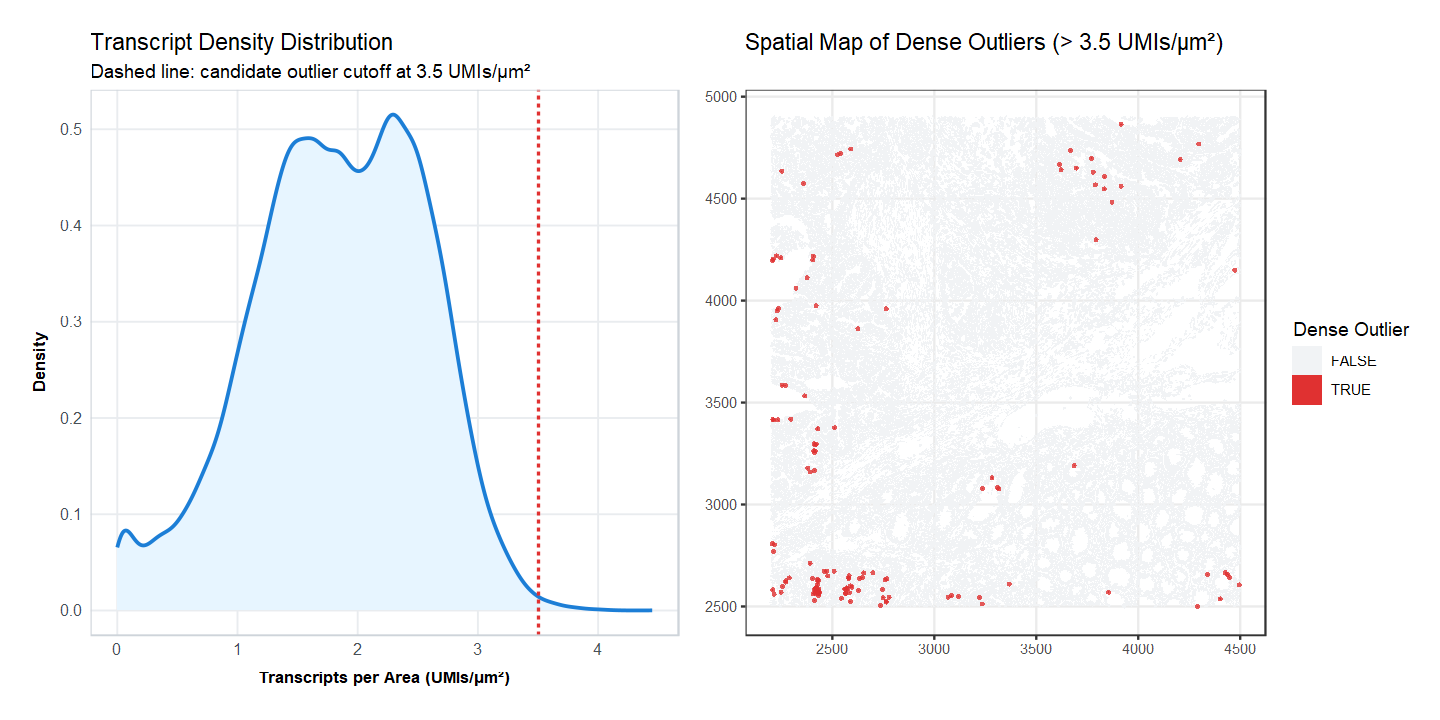

In [43]:
# Set canvas dimensions
options(repr.plot.width = 12, repr.plot.height = 6)

# Density distribution
p_cpa_dist <- ggplot(as.data.frame(colData(sfe)), aes(x = counts_per_area)) +
  geom_density(fill = "#e7f5ff", color = "#1c7ed6", linewidth = 0.8) +
  geom_vline(xintercept = 3.5, color = "#e03131", linetype = "dashed", linewidth = 0.7) +
  labs(
    title    = "Transcript Density Distribution",
    subtitle = "Dashed line: candidate outlier cutoff at 3.5 UMIs/µm²",
    x        = "Transcripts per Area (UMIs/µm²)",
    y        = "Density"
  )

# Spatial mapping of dense outliers
p_cpa_spatial <- plotSpatialFeature(
  sfe, 
  features        = "dense_outlier", 
  colGeometryName = "cellSeg", 
  show_axes       = TRUE
) +
  scale_fill_manual(values = c("FALSE" = "#f1f3f5", "TRUE" = "#e03131"), name = "Dense Outlier") +
  labs(
    title    = "Spatial Map of Dense Outliers (> 3.5 UMIs/µm²)"
  ) +
  geom_sf(
    data  = flagged_dense_outliers, 
    color = "#e03131", 
    size  = 0.8, 
    shape = 16, 
    alpha = 0.8
  ) +
  theme(legend.position = "right")

p_cpa_dist | p_cpa_spatial

Transcript density displays a well-behaved unimodal distribution with a **median of 1.70 UMIs/µm²**, with >99% of cells falling within the normal physiological range (0.5–3.0 UMIs/µm²). Only **135 cells (0.26%)** exceed the candidate threshold of 3.5 UMIs/µm².

Spatially, these cells do not exhibit random noise or optical flare artifacts. Instead, they partition into two distinct regimes:

- **Adenocarcinoma core packing:** The focal clusters in the upper right and lower left localize strictly within the hyper-proliferative cores of invasive tumor nests, reflecting high ribosomal and transcriptional density characteristic of malignant colorectal epithelium.
- **Peripheral boundary truncation:** A minority of outliers align along the extreme tissue crop boundaries (X ≈ 2200, Y ≈ 2500), where mechanical sectioning or ROI cropping mechanically truncated cell polygons, artificially shrinking the denominator (`cell_area`).

Because these dense cells primarily represent authentic malignant phenotypes rather than technical contamination, applying a blanket upper density filter would disproportionately cull hyper-transcriptionally active adenocarcinoma cells. We therefore retain them in downstream analyses.

## Spatial outlier detection

### Biological motivation: detached debris and vascular lumina

In imaging-based _in situ_ transcriptomics, automated segmentation pipelines operate across the entire optical scan. However, microtome slicing and wet-mounting can dislodge small cytoplasmic fragments, mucus droplets, or individual detached cells onto the glass slide, microns away from the cohesive tissue boundary. Moreover, large anatomical voids, such as the lumens of colonic crypts or dilated **submucosal blood vessels (arterioles and venules)**, are largely devoid of nucleated structural cells, packed instead with anucleate erythrocytes or occasional circulating leukocytes.

Cells located unusually far from any neighbors are typically non-viable debris or isolated detachments. In downstream spatial analyses (such as spatial autocorrelation, Delaunay triangulation, or cell-cell neighborhood graphs), isolated singletons distort boundary topologies and inflate spatial lag metrics. Identifying and flagging these spatial outliers ensures that downstream spatial networks reflect authentic, cohesive tissue architecture.

### k-nearest-neighbor (k-NN) distance distributions

To quantify local isolation without assuming an arbitrary global density threshold, we build a **$k$-nearest-neighbor ($k$-NN) graph** ($k = 5$) on the physical 2D centroid coordinates of all cells ($X, Y$ in micrometers):

$$
\mathbf{X} \in \mathbb{R}^{N \times 2}, \quad N = 52{,}569
$$

For each cell $i$, we compute Euclidean distances to its $k$ closest neighbors using the C++-accelerated _Approximate Nearest Neighbor_ library (`BiocNeighbors::AnnoyParam()`).

In [44]:
# Extract 2D physical centroid coordinates in microns
cell_coords <- spatialCoords(sfe)[, 1:2]

# Construct 5-nearest-neighbor graph using Annoy approximate search
set.seed(42)
knn_graph <- BiocNeighbors::findKNN(
  cell_coords, 
  k       = 5, 
  BNPARAM = BiocNeighbors::AnnoyParam()
)

In [45]:
# Check matrix dimensions (52,569 rows x 5 columns)
print(dim(knn_graph$distance))

[1] 52569     5


In [46]:
# View summary statistics across each of the 5 neighbor distances
summary(knn_graph$distance, digits = 2)

       V1              V2             V3             V4             V5      
 Min.   : 0.96   Min.   : 2.6   Min.   : 3.3   Min.   : 4.1   Min.   : 4.7  
 1st Qu.: 5.14   1st Qu.: 6.4   1st Qu.: 7.5   1st Qu.: 8.6   1st Qu.: 9.6  
 Median : 6.21   Median : 7.6   Median : 8.9   Median :10.2   Median :11.3  
 Mean   : 6.53   Mean   : 8.1   Mean   : 9.5   Mean   :10.8   Mean   :12.0  
 3rd Qu.: 7.51   3rd Qu.: 9.2   3rd Qu.:10.8   3rd Qu.:12.3   3rd Qu.:13.6  
 Max.   :74.92   Max.   :75.8   Max.   :84.3   Max.   :88.9   Max.   :90.4  

Because the returned distance vector $\mathbf{d}_i = (d_{i, 1}, d_{i, 2}, \dots, d_{i, 5})$ is sorted in ascending order ($d_{i, 1} \le d_{i, 2} \le \dots \le d_{i, 5}$):

* **Nearest-neighbor distance ($d_{\min} = d_{i, 1}$):** Measures the distance to the single closest adjacent cell. In densely packed colonic epithelium, the median $d_{\min}$ is only ≈ 6.2 µm (less than one cell diameter). A cell with `dist_knn_min` > 30 µm is separated from *every other cell* by more than 2–3 cell diameters, identifying severe topological isolation.
* **Neighborhood dispersion distance ($d_{\max} = d_{i, 5}$):** Measures the distance to the 5th nearest neighbor. In cohesive tissue, median $d_{\max}$ is ≈ 11.3 µm. A cell with `dist_knn_max` > 50 µm indicates an abnormally sparse, fragmented microenvironment lacking local support.

Cells satisfying `dist_knn_min` ≤ 30 µm and `dist_knn_max` ≤ 50 µm are designated as cohesive **`main_tissue`**.

In [47]:
# Extract minimum distance (column 1) and 5th-neighbor distance (column 5)
min_dist <- knn_graph$distance[, 1]
max_dist <- knn_graph$distance[, 5]

# Store distance metrics and spatial outlier flags in colData
sfe[["dist_knn_min"]]         <- min_dist
sfe[["dist_knn_max"]]         <- max_dist
sfe[["flag_spatial_outlier"]] <- (min_dist > 30 | max_dist > 50)  # logical OR (|)
sfe[["main_tissue"]]          <- !sfe[["flag_spatial_outlier"]]

# Prepare data frame for side-by-side diagnostic plotting
df_dist <- data.frame(
  min_dist = min_dist,
  max_dist = max_dist
)

In [48]:
# Extract distance metrics and key QC features for the 6 outlier cells
colData(sfe)[
  sfe[["flag_spatial_outlier"]], 
  c("dist_knn_min", "dist_knn_max", "nCounts", "cell_area")]

DataFrame with 6 rows and 4 columns
           dist_knn_min dist_knn_max   nCounts cell_area
              <numeric>    <numeric> <numeric> <numeric>
ikbmobln-1      43.8335      61.1093         6   53.8714
mefambpm-1      36.2193      38.0581        35   29.2613
ofebbglb-1       6.8949      90.4045        18   84.0358
ofebgmaf-1       6.8949      87.4240        21   87.3773
ofecagic-1      74.9154      77.2504        29  170.6003
offdmgjf-1      57.1025      62.0710         4  187.7597

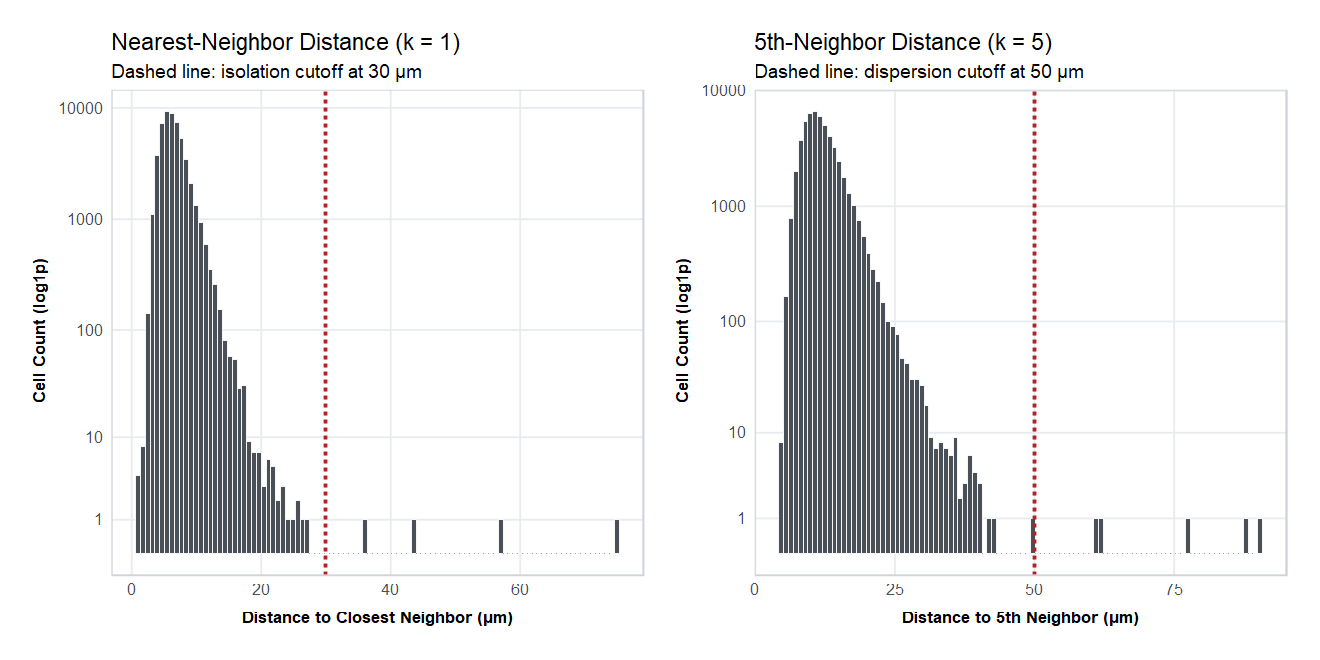

In [49]:
# Set canvas dimensions for dual diagnostic histograms
options(repr.plot.width = 11, repr.plot.height = 5.5)

# Nearest neighbor distance (d_min)
p_min <- ggplot(df_dist, aes(x = min_dist)) +
  geom_histogram(bins = 100, fill = "#495057", color = "white", linewidth = 0.2) +
  geom_vline(xintercept = 30, color = "firebrick", linetype = "dashed", linewidth = 0.8) +
  scale_y_continuous(transform = "log1p", breaks = c(1, 10, 100, 1000, 10000)) +
  labs(
    title    = "Nearest-Neighbor Distance (k = 1)",
    subtitle = "Dashed line: isolation cutoff at 30 µm",
    x        = "Distance to Closest Neighbor (µm)",
    y        = "Cell Count (log1p)"
  )

# 5th-neighbor distance (d_max)
p_max <- ggplot(df_dist, aes(x = max_dist)) +
  geom_histogram(bins = 100, fill = "#495057", color = "white", linewidth = 0.2) +
  geom_vline(xintercept = 50, color = "firebrick", linetype = "dashed", linewidth = 0.8) +
  scale_y_continuous(transform = "log1p", breaks = c(1, 10, 100, 1000, 10000)) +
  labs(
    title    = "5th-Neighbor Distance (k = 5)",
    subtitle = "Dashed line: dispersion cutoff at 50 µm",
    x        = "Distance to 5th Neighbor (µm)",
    y        = "Cell Count (log1p)"
  )

# Display side-by-side using patchwork
p_min | p_max

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


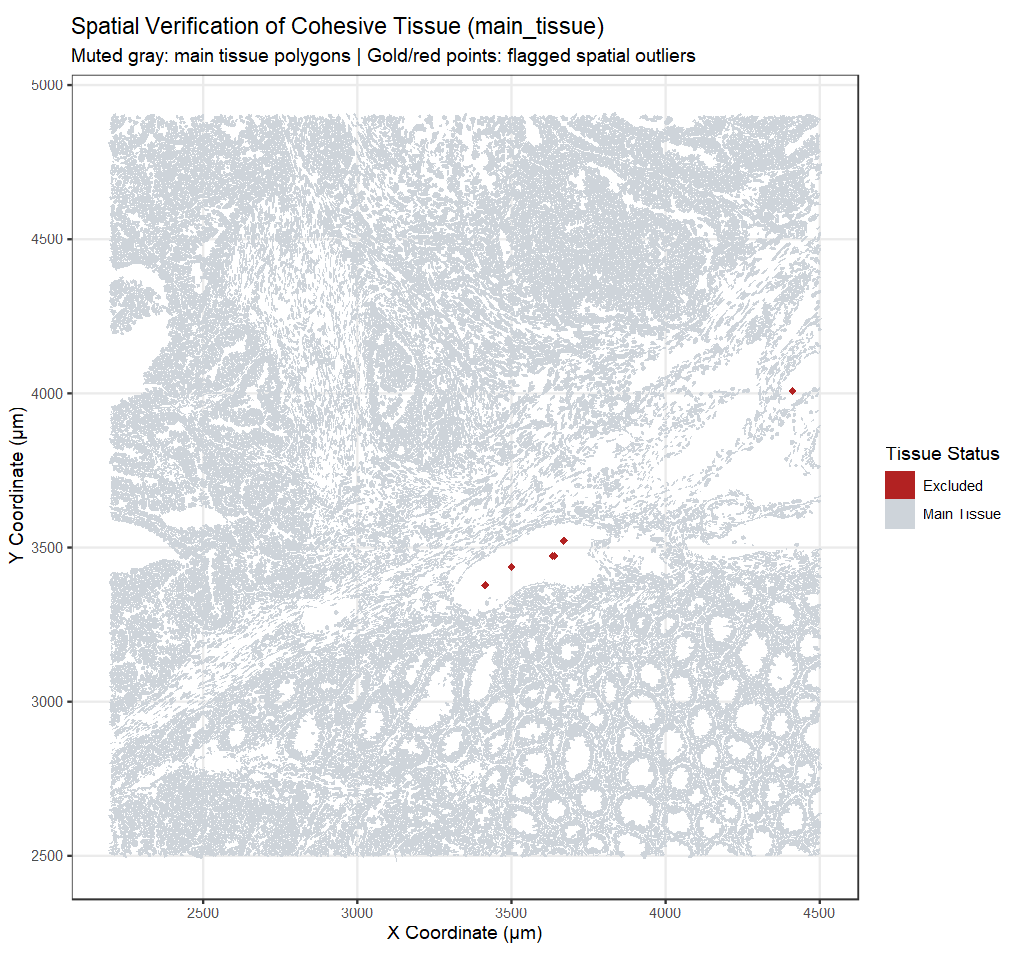

In [50]:
# Set canvas dimensions for high-resolution spatial overlay
options(repr.plot.width = 8.5, repr.plot.height = 8)

# Extract centroids of flagged spatial outliers for high-contrast overlay
flagged_outlier_centroids <- centroids(sfe)[sfe[["flag_spatial_outlier"]], ]

# Map main tissue polygons and highlight isolated outliers with prominent red markers
plotSpatialFeature(
  sfe, 
  features        = "main_tissue", 
  colGeometryName = "cellSeg", 
  show_axes       = TRUE
) +
  scale_fill_manual(
    values = c("FALSE" = "firebrick", "TRUE" = "#ced4da"),
    name   = "Tissue Status",
    labels = c("FALSE" = "Excluded", "TRUE" = "Main Tissue")
  ) +
  geom_sf(
    data  = flagged_outlier_centroids, 
    color = "firebrick", 
    size  = 2, 
    shape = 18, 
  ) +
  labs(
    title    = "Spatial Verification of Cohesive Tissue (main_tissue)",
    subtitle = "Muted gray: main tissue polygons | Gold/red points: flagged spatial outliers",
    x        = "X Coordinate (µm)",
    y        = "Y Coordinate (µm)"
  ) +
  theme(legend.position = "right")

Only **6 cells (0.011%)** are flagged as spatial outliers (4 with $d_{\min} > 30\text{ µm}$ and 5 with $d_{\max} > 50\text{ µm}$). Spatially, these 6 cells map directly inside the large, hollow submucosal vascular lumina (congested venules/arterioles) at X ≈ 3200–3600 µm, Y ≈ 3300–3700 µm, and along the extreme peripheral resection tear. Within blood vessel cavities, solitary circulating cells (such as intravascular monocytes or marginated lymphocytes) naturally lack structural epithelial or fibroblastic neighbors.

## Gene-level QC & noise modeling

### Biological and statistical motivation

In targeted imaging-based spatial transcriptomics, QC extends beyond cell-level metrics to the individual genes comprising the panel. While cell filtering removes damaged geometries and anucleate fragments, gene-level filtering verifies whether targeted probes capture genuine biological expression or remain indistinguishable from optical background noise. 

Unlike discovery platforms that sequence the entire transcriptome, targeted _in situ_ platforms like 10x Xenium interrogate a curated panel (here, 422 human colon cancer targets) alongside dedicated **negative control probes** (non-targeting hybridizations) and **negative control codewords** (unassigned optical barcodes, totaling 119 controls). By evaluating how transcript counts vary across all 52,569 cells, we can directly quantify the stochastic boundary separating physical background fluorescence from authentic transcriptional signal. 

#### Technical noise as a Poisson process

The molecular counting of individual fluorescent spots across discrete cellular compartments follows well-defined statistical distributions. If fluorescent spots arise purely from non-specific probe binding, optical bleed-through, or random misdecoding, these events occur independently at a _constant, uniform rate_ across the slide. Under this memoryless null model, the count $Y_{gi}$ of negative control $g$ in cell $i$ follows a Poisson distribution parameterized solely by its mean rate $\mu_g$:

$$
Y_{gi} \sim \text{Poisson}(\mu_g) \implies \mathbb{E}[Y_g] = \mu_g, \quad \operatorname{Var}(Y_g) = \mu_g
$$

In a log–log coordinate space comparing variance against mean:

$$
\log_{10}(\operatorname{Var}(Y_g)) = \log_{10}(\mu_g)
$$

This relationship defines the **Poisson identity line ($y = x$)**, representing the theoretical lower bound of technical noise. Any feature whose variance strictly equals its mean across all cells exhibits zero biological regulation and reflects purely random Poisson arrival.

#### Biological overdispersion and Negative Binomial variance

In contrast, authentic biological genes are regulated across distinct histological microenvironments. In colorectal tissue, an epithelial oncogene (e.g., `CEACAM5`) is expressed abundantly within neoplastic crypts but remains completely repressed in smooth muscle fibers and stromal fibroblasts. This cell-type heterogeneity introduces extra-Poisson variation across cells.

We model this biological heterogeneity using a Negative Binomial (Gamma-Poisson mixture) framework:

$$
Y_{gi} \sim \text{Negative Binomial}(\mu_g, \alpha_g) \implies \operatorname{Var}(Y_g) = \mu_g + \alpha_g \mu_g^2
$$

where $\alpha_g > 0$ represents the gene-specific biological overdispersion parameter. 

Expressing this relationship through the **Index of Dispersion** (Variance-to-Mean Ratio, VMR):

$$
\operatorname{VMR}_g = \frac{\operatorname{Var}(Y_g)}{\mu_g} = 1 + \alpha_g \mu_g > 1
$$

Because $\alpha_g > 0$, **all genuine biological genes carrying cellular specificity must lie strictly above the diagonal ($y > x$)**. Furthermore, as mean expression $\mu_g$ increases, the quadratic biological overdispersion term ($\alpha_g \mu_g^2$) rapidly dominates the linear Poisson sampling term ($\mu_g$), causing the cloud of biological genes to diverge upward from the technical identity line.

In [51]:
# Compute mean and sparse sample variance across all 52,569 cells
# (sparseMatrixStats avoids densifying the matrix into RAM)
rowData(sfe)[["means"]]  <- rowMeans(counts(sfe))
rowData(sfe)[["vars"]]   <- sparseMatrixStats::rowVars(counts(sfe))
rowData(sfe)[["is_neg"]] <- rowData(sfe)[["Type"]] != "Gene Expression"

# Convert rowData to a clean data frame for ggplot2 and tabular prints
df_genes <- as.data.frame(rowData(sfe))
df_genes[["feature_class"]] <- factor(
  ifelse(df_genes[["is_neg"]], "Negative Control", "Biological Gene"),
  levels = c("Negative Control", "Biological Gene")
)

Warning message in scale_y_log10(labels = scales::label_log(), breaks = c(1e-05, :
"log-10 transformation introduced infinite values."
Warning message in scale_y_log10(labels = scales::label_log(), breaks = c(1e-05, :
"log-10 transformation introduced infinite values."
Warning message:
"Removed 23 rows containing non-finite outside the scale range
(`stat_ydensity()`)."
Warning message in scale_x_log10(labels = scales::label_log(), breaks = c(1e-05, :
"log-10 transformation introduced infinite values."
Warning message in scale_y_log10(labels = scales::label_log(), breaks = c(1e-05, :
"log-10 transformation introduced infinite values."


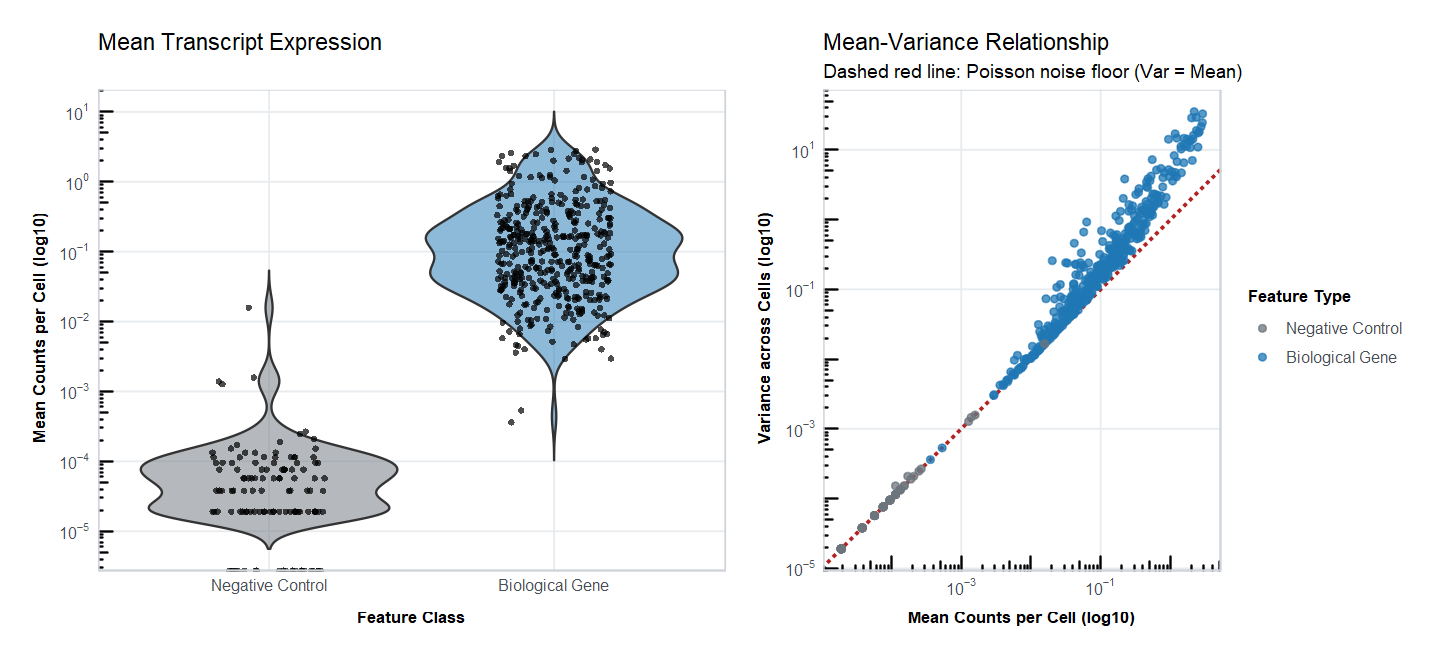

In [52]:
# Set canvas dimensions for dual gene QC panels
options(repr.plot.width = 12, repr.plot.height = 5.5)

# Panel 1: Distribution of mean expression (Biological vs Control)
p_means <- ggplot(df_genes, aes(x = feature_class, y = means, fill = feature_class)) +
  geom_violin(alpha = 0.5, scale = "width", trim = FALSE) +
  geom_jitter(width = 0.2, size = 1.2, alpha = 0.7, shape = 16) +
  scale_y_log10(
    labels = scales::label_log(),
    breaks = c(1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10)
  ) +
  scale_fill_manual(values = c("Negative Control" = "#6c757d", "Biological Gene" = "#1f77b4")) +
  annotation_logticks(sides = "l") +
  labs(
    title = "Mean Transcript Expression",
    x     = "Feature Class",
    y     = "Mean Counts per Cell (log10)"
  ) +
  theme(legend.position = "none")

# Panel 2: Mean-Variance overdispersion vs. Poisson identity line
p_mean_var <- ggplot(df_genes, aes(x = means, y = vars, color = feature_class)) +
  geom_abline(slope = 1, intercept = 0, color = "firebrick", linetype = "dashed", linewidth = 0.8) +
  geom_point(alpha = 0.75, size = 1.5) +
  scale_x_log10(labels = scales::label_log(), breaks = c(1e-5, 1e-3, 1e-1, 10)) +
  scale_y_log10(labels = scales::label_log(), breaks = c(1e-5, 1e-3, 1e-1, 10)) +
  scale_color_manual(values = c("Negative Control" = "#6c757d", "Biological Gene" = "#1f77b4")) +
  annotation_logticks(sides = "bl") +
  coord_equal() +
  labs(
    title = "Mean-Variance Relationship",
    subtitle = "Dashed red line: Poisson noise floor (Var = Mean)",
    x     = "Mean Counts per Cell (log10)",
    y     = "Variance across Cells (log10)",
    color = "Feature Type"
  ) +
  theme(legend.position = "right")

# Display side-by-side using patchwork
p_means | p_mean_var

The median mean expression of biological genes is **0.1010 UMIs/cell**, which is **>2,600-fold higher** than the negative control median (**0.000038 UMIs/cell**). The vast majority of the 422 biological targets operate orders of magnitude above the optical detection threshold. 

Moreover, the 119 negative control probes and codewords fall strictly along the **Poisson identity line (y = x)**, verifying that false-positive decoding and non-specific hybridization follow random, uncoordinated Poisson arrival processes (Var ≈ Mean).

In contrast, biological genes sit strictly above the identity line (Var > Mean), driven by cell-type-specific transcriptional variance (Var = μ + αμ²). Spatially compartmentalized markers of normal mucosa (`PIGR`, `CLCA1`), tumor-associated macrophages (`SPP1`, `CHI3L1`), and crypt stem/proliferative niches (`OLFM4`) exhibit the highest overdispersion ratios, reaching 14.5–17.3.

In [53]:
# # Compute the Index of Dispersion (VMR = Variance / Mean) for all features
# rowData(sfe)[["dispersion"]] <- rowData(sfe)[["vars"]] / rowData(sfe)[["means"]]

# # Extract biological genes into a clean data frame
# df_bio <- as.data.frame(rowData(sfe)) |>
#   filter(!is_neg) |>
#   select(means, vars, dispersion)

# Extract biological genes and derive dispersion on-the-fly without altering rowData(sfe)
df_bio <- df_genes |>
  filter(!is_neg) |>
  mutate(dispersion = vars / means) |>
  select(means, vars, dispersion)

# Inspect the top 5 most overdispersed biological markers
df_bio |> 
  slice_max(order_by = dispersion, n = 5)

,means,vars,dispersion
,<dbl>,<dbl>,<dbl>
SPP1,0.2205482,3.8189576,17.31575
PIGR,2.1884571,35.2526624,16.10846
CLCA1,0.9373966,14.1864437,15.13388
CHI3L1,0.0629078,0.9237362,14.68397
OLFM4,1.1676654,16.9845951,14.54577


A subset of 52 biological targets (12.3%) falls below the maximum negative control ceiling (0.0158 UMIs/cell), led by patient-absent TCR clonotype probes (`Clonotype1_TRA2`, `Clonotype1_TRB`), scarce T-cell markers (`CD7`), and tumor-suppressed mucosal signals (`GUCA2A`). 

Visually, these 52 low-abundance targets form the lower tail of the biological violin that dips below the highest negative control point (0.0158 UMIs/cell), and correspond to the blue biological points on the lower left ($x < 10^{-1.8}$) that hug the red dashed diagonal line (y = x), where ultra-low sampling depth causes biological overdispersion to collapse into the Poisson noise floor.

Because this specific tissue crop from Patient P2 naturally lacks those specific T-cell receptor clones and rare immune lineages, these targets remain at basal levels without indicating technical probe failure.

In [54]:
# Maximum mean observed across all 119 negative controls
max_neg_mean <- max(rowData(sfe)[["means"]][rowData(sfe)[["is_neg"]]])
cat(
  sprintf(
    "Maximum negative control mean: %.6f UMIs/cell\n", max_neg_mean))

# How many biological genes have mean expression below this technical ceiling?
low_genes <- df_bio |> 
  filter(means <= max_neg_mean)
cat(
  sprintf(
    "Biological genes falling within negative control range: %d / %d\n", 
    nrow(low_genes), nrow(df_bio)))

Maximum negative control mean: 0.015751 UMIs/cell
Biological genes falling within negative control range: 52 / 422


In [55]:
# Inspect the bottom 5 lowest-expressing biological targets
df_bio |> 
  slice_min(order_by = means, n = 5)

,means,vars,dispersion
,<dbl>,<dbl>,<dbl>
Clonotype1_TRA2,0.0003614297,0.0003613060,0.9996576
Clonotype1_TRB,0.0005326333,0.0005323597,0.9994864
CD7,0.0029294832,0.0029970488,1.0230640
GUCA2A,0.0029485058,0.0030920518,1.0486843
Clonotype1_TRA1,0.0035952748,0.0042291982,1.1763213


### Xenium versus scRNA-seq and bulk RNA-seq (`voom`)

In bulk RNA-seq, `voom` models heteroscedasticity across *biological replicates* (plotting $\sqrt{\text{residual standard deviation}}$ against average log₂ counts) to estimate precision weights for linear modeling. In contrast, _in situ_ spatial transcriptomics measures discrete single-molecule counts across individual cells within a single tissue section, directly probing microscopic stochasticity. 

In droplet-based scRNA-seq, every library is sequenced from whole-transcriptome capture without physical negative control probes. Feature selection algorithms (such as `scran::modelGeneVar()` or `Seurat::FindVariableFeatures()`) must estimate technical noise empirically by fitting a smoothing spline across all endogenous genes, assuming that the majority of low-to-medium expressed genes reflect technical baseline noise. 

In Xenium, we do not need to guess where technical noise ends: the **119 negative controls provide an empirical ground-truth baseline**. We can directly verify whether negative controls follow the theoretical Poisson diagonal (y = x) and objectively determine which biological genes rise above this physical detection floor.

## Final object filtering

### Integrated multi-factorial filtering strategy

Robust QC in spatial transcriptomics requires an integrated, multi-factorial strategy combining optical background, molecular depth, cell morphology, and spatial contiguity. We synthesize our findings into five calibrated quality gates:

1. **Low optical noise (`subsets_any_neg_percent < 5`):** Restricts false-positive hybridization and optical crosstalk to **< 5%** of total cellular UMIs.
2. **Transcriptional depth (`nCounts >= 10`):** Ensures sufficient endogenous library size, eliminating empty segmentation artifacts and permeabilization dropouts.
3. **Gene diversity (`nGenes >= 5`):** Enforces multi-probe transcriptional complexity, weeding out mono-probe fluorescent precipitates.
4. **Nuclear confirmation (`has_nuclei`):** Retains only authentic nucleated cell bodies (`nucleus_area > 0`), discarding non-viable anucleate cytoplasmic caps and detached mucus fragments.
5. **Tissue contiguity (`main_tissue`):** Enforces 5-NN spatial neighborhood membership (`dist_knn_min` ≤ 30 µm and `dist_knn_max` ≤ 50 µm), eliminating detached resection tears and floating intravascular debris.

In [56]:
# Define individual quality flags using strict double-bracket accessors
pass_neg_pct <- !is.na(sfe[["subsets_any_neg_percent"]]) & sfe[["subsets_any_neg_percent"]] < 5
pass_ncounts <- sfe[["nCounts"]] >= 10
pass_ngenes  <- sfe[["nGenes"]] >= 5
pass_nuclei  <- sfe[["has_nuclei"]]
pass_tissue  <- sfe[["main_tissue"]]

By evaluating both the **marginal attrition** (cells passing each filter in isolation) and the **joint conjunction** (cells passing all five filters simultaneously), we quantify the exact contribution of each biological and technical filter.

In [57]:
# Construct the joint quality filter/flag (logical AND)
sfe[["qc_keep"]] <- pass_neg_pct & pass_ncounts & pass_ngenes & pass_nuclei & pass_tissue

In [58]:
# Assemble the comparative filtration report table
df_qc_summary <- data.frame(
  Criterion = c(
    "Low background (neg % < 5)",
    "Library depth (nCounts >= 10)",
    "Gene complexity (nGenes >= 5)",
    "Nuclear confirmation (has_nuclei)",
    "Spatial contiguity (main_tissue)",
    "ALL CRITERIA COMBINED (qc_keep)"
  ),
  Cells_Passing = c(
    sum(pass_neg_pct),
    sum(pass_ncounts),
    sum(pass_ngenes),
    sum(pass_nuclei),
    sum(pass_tissue),
    sum(sfe[["qc_keep"]])
  )
) |>
  mutate(
    Cells_Removed = ncol(sfe) - Cells_Passing,
    Pct_Removed  = round(100 * (1 - Cells_Passing / ncol(sfe)), 2)
  )

print(df_qc_summary, row.names = FALSE)

                         Criterion Cells_Passing Cells_Removed Pct_Removed
        Low background (neg % < 5)         52383           186        0.35
     Library depth (nCounts >= 10)         51109          1460        2.78
     Gene complexity (nGenes >= 5)         51716           853        1.62
 Nuclear confirmation (has_nuclei)         49152          3417        6.50
  Spatial contiguity (main_tissue)         52563             6        0.01
   ALL CRITERIA COMBINED (qc_keep)         47671          4898        9.32


From an initial dataset of **52,569 segmented cells**, our multi-factorial QC protocol retains **47,671 high-confidence cells**, removing **4,898 cells (9.32%)**:

* **Nuclear exclusion (`has_nuclei`):** Represents the single largest contributor to cell attrition (**3,417 cells, 6.50%**). These segments primarily correspond to authentic cytoplasmic tangential slices cut above or below the nuclear equator during microtome sectioning, alongside detached mucosal droplets.
* **Transcriptional depth & complexity:** Removes **1,460 low-depth cells (2.78%)** and **853 low-complexity cells (1.62%)**, predominantly concentrated within transcript-sparse submucosal smooth muscle fibers and acellular vascular cavities.
* **Optical noise (`neg % < 5`):** Excludes **186 cells (0.35%)** with elevated non-specific probe binding or optical misdecoding, ensuring that background noise does not distort downstream clustering.
* **Spatial contiguity (`main_tissue`):** Purges the **6 spatial outliers (0.01%)** floating within vascular lumina and peripheral resection tears, guaranteeing that downstream neighborhood graphs connect only cohesive tissue parenchyma.

### Sequential 2D pruning

Having finalized our joint threshold (`qc_keep`), we now commit these decisions through **sequential 2D pruning**:

1. **Column slicing (cells):** We first subset the object across columns to retain only the 47,671 high-confidence cells passing all five criteria.
2. **Row pruning (genes):** Because purging compromised cells dynamically alters gene-level expression sums, we immediately evaluate the remaining matrix to prune any newly unexpressed targets (`rowSums(counts) > 0`). This prevents zero-variance features from introducing division-by-zero (`NaN`) artifacts during downstream normalization and PCA.

In [59]:
# Step 1: Column-wise pruning (cells) — Retain high-confidence cells passing composite QC
sfe_qc <- sfe[, sfe[["qc_keep"]]]

# Step 2: Row-wise pruning (genes) — Prune genes that became inactive after cell removal
genes_expressed <- rowSums(counts(sfe_qc)) > 0
sfe_qc <- sfe_qc[genes_expressed, ]

In [60]:
# Construct a structured summary table of the sequential 2D pruning
df_pruning_summary <- data.frame(
  Dimension = c(
    "Cells (columns)", 
    "Total Features (rows)", 
    "Biological Genes"
  ),
  Pre_Filtering = c(
    ncol(sfe), 
    nrow(sfe), 
    sum(rowData(sfe)[["Type"]] == "Gene Expression")
  ),
  Post_Filtering = c(
    ncol(sfe_qc), 
    nrow(sfe_qc), 
    sum(rowData(sfe_qc)[["Type"]] == "Gene Expression")
  )
) |>
  mutate(
    Difference   = Pre_Filtering - Post_Filtering,
    Pct_Retained = round(100 * Post_Filtering / Pre_Filtering, 2)
  )

print(df_pruning_summary, row.names = FALSE)

             Dimension Pre_Filtering Post_Filtering Difference Pct_Retained
       Cells (columns)         52569          47671       4898        90.68
 Total Features (rows)           541            515         26        95.19
      Biological Genes           422            422          0       100.00


Following the removal of 4,898 compromised cells (9.32%), **all 422 targeted biological genes** remain actively transcribed across the remaining high-confidence cells (> 0 counts). Zero biological targets dropped out, proving that our cell-filtering gates did not inadvertently excise any specialized tissue lineages or rare cell types.

Total panel features decrease from **541 to 515** (95.19% retained). The **26 pruned features were exclusively negative control probes and codewords** whose only spurious detections occurred within the discarded anucleate fragments and debris. Once those cells were removed, these technical probes became completely inactive across the cohesive tissue parenchyma. Pruning them eliminates dead features and prevents zero-variance division-by-zero errors in downstream modeling.

In [61]:
# Inspect the final dimensions of the filtered object
sfe_qc

class: SpatialFeatureExperiment 
dim: 515 47671 
metadata(1): Samples
assays(1): counts
rownames(515): ABCC8 ACP5 ... UnassignedCodeword_0292
  UnassignedCodeword_0298
rowData names(10): ID Symbol ... vars is_neg
colnames(47671): ablhnkec-1 ablhpkkh-1 ... oikdllpb-1 oikeebja-1
colData names(39): transcript_counts control_probe_counts ...
  main_tissue qc_keep
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : x_centroid y_centroid
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (MULTIPOLYGON), nucSeg (MULTIPOLYGON) 

Graphs:
sample01: 

After executing both filtering steps, our clean, QC-filtered `SpatialFeatureExperiment` object retains **47,671 high-quality cells** (removing 4,898 compromised cells, 9.32%) and **515 features** (including all **422 targeted biological genes** and 93 active control probes).

> We deliberately preserve active negative controls alongside endogenous transcripts because downstream spatial modeling and deconvolution algorithms rely on this empirical noise baseline to quantify optical background and benchmark false discovery rates.

## Translating imaging QC to Visium HD segmented cells

Because both datasets are represented in Bioconductor as `SpatialFeatureExperiment` (`sfe`) objects containing vector polygon geometries (`cellSeg`, `nucSeg`, `centroids`), the computational workflows are **largely interoperable**, but their biological and physical interpretations differ across several key dimensions:

### Directly Transferable Components (Morphology & Spatial Contiguity)

In Space Ranger v4+, Visium HD segments cells by identifying nuclei from H&E or DAPI images via StarDist, subsequently expanding nuclear boundaries outward by 2–5 µm (or until meeting adjacent cells). Because `sfe` stores both `cellSeg` and `nucSeg` polygons, calculating nuclear-to-cell ratio (`prop_nuc`) and screening for morphologically distorted polygons (e.g., StarDist over-expansion into acellular collagen) transfers directly.

Evaluating the ratio of endogenous library size to segmented polygon area (`counts_per_area`; UMIs/µm²) is equally vital in Visium HD. It immediately identifies segmented boundaries that artificially clipped high-density clusters or under-segmented multiple tightly packed cells.

Finally, computing 5-nearest-neighbor centroid distances via `BiocNeighbors::findKNN()` is platform-agnostic. While for segmented Visium data we applied `SpotSweeper` to detect local expression drops, $k$-NN distance thresholding provides a complementary, purely topological filter that purges isolated debris, resection tears, and cells within vascular lumina across both platforms (`main_tissue`).

### Platform-Specific Divergences

| QC Dimension | 10x Xenium | Visium HD Segmented | Analytical Adaptation for Visium HD |
| :--- | :--- | :--- | :--- |
| **Technical Noise Floor** | **119 Negative Control Probes & Codewords:** Direct empirical baseline of optical noise and misdecoding. | **None:** Lacks non-targeting barcodes; uses whole-transcriptome capture probes. | Rely on **mitochondrial percentage (`subsets_Mito_percent`)** and sequencing quality scores (Q ≥ 30). |
| **Cell Permeabilization QC** | Mitochondrial probes typically omitted from targeted panels; anucleate tracking proxies cytoplasmic integrity. | **Mitochondrial UMI fraction:** Extensively used via `SpotSweeper::localOutliers()` to detect autolytic membrane rupture. | Use mitochondrial fraction as the primary indicator of lysed/permeabilized cells. |
| **Spatial Resolution of Counting** | **Subcellular optical coordinates (< 0.1 µm):** Exact single-molecule $(x, y, z)$ centroids assigned to 3D cell volumes. | **2-µm square grid rasterization:** Planar oligonucleotide array; counts aggregated from 2-µm bins intersecting polygons. | Discretization effects: segmented cells overlapping bin boundaries experience edge-pixel binning artifacts. |
| **Noise Stochasticity** | **Unamplified Poisson arrivals:** Linear relationship (Var ≈ Mean) for negative controls on log-log scales. | **Negative Binomial / Overdispersed Sequencing:** PCR amplification and flowcell optical duplication introduce extra-Poisson variance. | Standardize counts using sequencing depth size factors (`scran::computeSumFactors()`) or `SCTransform`. |
| **Anucleate Segments** | **Authentic cytoplasmic caps (6.5%):** Planar 5-µm slicing cuts cells above/below the nuclear equator. | **Virtually absent (0%):** Space Ranger seeds cell polygons strictly from detected StarDist nuclei. | Filtering `has_nuclei` is redundant in standard Space Ranger outputs unless custom cell-boundary segmentations are imported. |

### Segmentation as a Multi-Omic Bridge

With Visium segmented data, QC treated cell polygons primarily as spatial containers for sequencing reads. Here, we interrogated the **morphology of the segmentation itself**, evaluating optical thickness, nuclear filling fractions, and boundary-to-interior transcript localization. 

Synthesizing both approaches demonstrates that segmented spatial transcriptomics is inherently multi-omic: it fuses classical computer-vision histopathology (nuclear morphology, tissue architecture) with quantitative genomics (library size, overdispersion, marker expression). Applying morphological QC alongside local spatial outlier screening establishes the most rigorous standard for high-resolution spatial biology across both optical and sequencing-based platforms.

## Data serialization & workspace cleanup

### Saving the filtered dataset

As established in our previous ingestion workflows, standard serialization functions (such as `.rds` or standard HDF5 savers) cannot reliably serialize the complex multi-layer `sf` spatial geometries (`cellSeg`, `nucSeg`) embedded within a `SpatialFeatureExperiment` object. 

To preserve the complete object architecture, we use the `alabaster.sfe` framework. This serializes our filtered count matrix, cell metadata, spatial coordinates, and vector polygon geometries into a modular, language-agnostic directory on disk. 

We save the object to `output/sfe_xenium_qc-filtered`, which serves as the primary input for downstream normalization and scaling in the upcoming notebooks.

In [62]:
# Define the standardized output directory path reflecting QC filtering
out_path <- "output/sfe_xenium_qc-filtered"

# Save the filtered SFE object and all associated spatial geometries to disk
saveObject(sfe_qc, out_path)

>>> Saving SpatialExperiment

>>> Saving colgeometries



In [63]:
# Inspect the modular directory structure created by alabaster.sfe
fs::dir_tree(out_path)

output/sfe_xenium_qc-filtered
├── assays
│   ├── 0
│   │   ├── matrix.h5
│   │   └── OBJECT
│   └── names.json
├── colgeometries
│   ├── 0
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 1
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 2
│   │   ├── map.parquet
│   │   └── OBJECT
│   └── names.json
├── column_data
│   ├── basic_columns.h5
│   └── OBJECT
├── coordinates
│   ├── array.h5
│   └── OBJECT
├── OBJECT
├── other_data
│   ├── list_contents.json.gz
│   └── OBJECT
├── row_data
│   ├── basic_columns.h5
│   └── OBJECT
└── _environment.json


### Session cleanup & memory reclamation

Because high-resolution spatial transcriptomic datasets and their associated cell-segmentation polygons occupy substantial memory (several gigabytes of RAM), it is best practice to clear the active workspace before proceeding. This ensures all allocated memory is returned to the system and prevents variable leakage into subsequent notebooks.

*(Note: In interactive IDEs such as RStudio or Positron, restarting the active R session via the menu bar is also recommended before opening the next notebook).*

In [64]:
# Clear all variables from the R environment
rm(list = ls())

# Aggressively trigger garbage collection to reclaim system RAM
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,12511344,668.2,22502318,1201.8,22502318,1201.8
Vcells,22270616,170.0,63961827,488.0,79952283,610.0
